# Week 4 - DX 799 mod C3 Deb Halder 2026 Fall - 1st Dataset- "Phishing Email Detection" 
As per the Kaggle Dataset Page page: The dataset specifies the email text body the type of emails which can be used to detect phishing emails by extensive analytics of the email text and classifying those using machine learning
- https://www.kaggle.com/datasets/subhajournal/phishingemails

- I will reuse the notebook of Week2 dataset in which I have used one of the data set from DX699 mod C2. I have the data analyzed and cleaned so it can be used in Week4. Week 4 related methods are given later in the notebook

### The notebook will have the initial dataset preparation followed with univariate and Bivariate analysis.

### We will then have the Week 2 related OLS with regularization and comparison of perfromance of 9 extracted features and TFIDF 5000 features. 
- We observe 9 extracted features has a poor classification performance 
- TFIDF has a very good performance but regularization takes lot of time
- Best Classification perfromance came with a threshold of 0.38(instead of 0.5)  but classification perfroamnce was very bad

### In Week4 I used  Logistic Regression and used feature scaling /standardization (Week 4 content is towards bottom of notebook)
- I used L2 regularization 
- Perfromed test for best Threshold value for best F1 score for the classificaition to cosider if an email content is spam(threshold of 0.48 gave the best result )
- Performed hyper parameter optimization identifiying best C value for regularization


### Observations from week 4

- **Strong performance**: Logistic regression with TF-IDF features and scaling achieved 97.26% holdout accuracy, 96.24% F1, and 0.9967 ROC-AUC, indicating excellent separation between safe and phishing emails.
- **Effective phishing detection**: Recall was 97.64%, with precision of 94.88%. Among 3,545 holdout emails, the model missed 30 phishing emails and incorrectly flagged 67 safe emails.
- **Best configuration**: The selected model used C = 0.001, balanced class weights, and a classification threshold of 0.48, which slightly favored detecting more phishing emails.
- **Good generalization**: Training F1 was 98.55%, compared with 96.24% on holdout data. This modest gap suggests some overfitting, while performance remained strong. Larger C values increased training scores without improving validation performance.
- **Scaling’s contribution**: These results demonstrate the effectiveness of the overall pipeline; a comparison without scaling is needed to establish whether scaling itself improved performance.
- **Logistic Regression With Grid Searchview** not only gave very good classification performance it is degree of order faster thant the OLS and results are better too 

#### Phishing Email dataset 1st dataset (Phishing Email Detection Kaggle)

- In the DX699-C2 I worked on a spam/phishing detection data set and used NLTK library to do  identify stopwords , and  created setof features based on patterns of words noticed. So I had to create features "http_url_count", "https_url_count", "sentence_count", "total_word_count", "urgency_terms_count", "account_terms_count", "threat_terms_count", "financial_terms_count", "official_terms_count". 
- In week2 this notebook I will compare the previous methods performance using the same old features but using linear regression with regularization and comapre with generating pattern based on TF-IDF score of words and use with 5000 bigrams . This is a method which I learned during advanced machine larning class  and I am expecting the performance of the classification will be better.
- Though the ulitmate intent is classification but I will use regression with three different regularizations for linear regression with Lasso , Ridge and Elastic net regularization and compare performance and create confusion matrix to evaluate performance of it as classification engine. We will use a probability threshold value of 0.5  and then find which threshold works best for OLS(will use SKlearn). So if 0.35 works best for OLS then we will use 0.35. We will also compare the RMSE and AUC besides confusion matrix to understnad perfromance.   

#### Week 2 Observation Summary from Execution

While Elastic Net with TF-IDF technically yields the single highest predictive score across metrics (F1: `0.953356`, ROC AUC: `0.996304`), Ridge Regression with TF-IDF is the clear winner for operational deployment. Ridge delivers virtually identical classification performance (F1: `0.946293`, ROC AUC: `0.995946`) while executing model fitting in **29.72 seconds**—making it **over 162 times faster** to train than Elastic Net (**4,818.31 seconds**).

Conversely, training linear models exclusively on 9 static count-based features fails completely in production scenarios, leading to severe underfitting, model collapse under L1 penalties, and massive false-positive rates.


### Execution Flow of Phishing Email Classification Pipeline

##### 1. Environment Setup & Data Acquisition
* **Library Imports:** Imports standard data processing, text, and machine learning libraries (`pandas`, `numpy`, `nltk`, `sklearn`, `kagglehub`, `hashlib`, `re`).
* **NLTK Downloads:** Downloads required tokenizer and stopword resources (`punkt`, `punkt_tab`, `stopwords`).
* **Data Download:** Fetches the `subhajournal/phishingemails` dataset from Kaggle via `kagglehub`, extracts the CSV to a local directory (`./dataset/phishing_email_1_dataset/`), loads it into a Pandas DataFrame (`df_phishing_email`), and cleans up the Kaggle cache.

##### 2. Data Cleaning & Label Encoding
* **Column Standardization:** Renames raw columns (`Email Text` $\rightarrow$ `text_combined`, `Email Type` $\rightarrow$ `label`) and drops unnecessary index columns (`Unnamed: 0`).
* **Target Mapping:** Maps string labels into binary integer targets (`Safe Email` $\rightarrow$ $0$, `Phishing Email` $\rightarrow$ $1$).
* **Basic Deduplication:** Strips whitespace, removes rows with missing/blank text, and drops exact duplicate records.

##### 3. Custom Text Preprocessing & Feature Engineering
* **HTML Parsing & Text Extraction:** Utilizes an `HTMLParser` subclass (`_VisibleText`) to strip script/style tags and unescape HTML entities to retrieve clean text.
* **Rule-Based Count Feature Extraction:** Identifies URLs (`http`/`https`), email addresses, total word length, sentence count, and frequency counts for domain-specific keyword categories (`urgency`, `account`, `threat`, `financial`, `official`).
* **Stopword Filtering:** Filters generic English stopwords while strictly protecting phrase-matching keywords and negations (e.g., "no", "not", "don't").

##### 4. Corpus Deduplication & Leakage-Free Grouping
* **Content Hashing:** Uses `hashlib.sha256` to compute SHA-256 hashes of normalized texts to remove exact duplicate contents and log conflicting labels.
* **Data Leakage Prevention:** Generates a `group_id` hash based on stopword-reduced content. This ensures near-duplicate emails are assigned to the same partition, preventing data leakage across train/validation/test folds.

##### 5. Stratified Grouped Train/Test Splitting
* **Holdout & Inner CV Splits:** Employs `StratifiedGroupKFold` to split the corpus into a training set and a held-out test set (approx. 80/20) based on `group_id`.
* **Inner Cross-Validation:** Configures an inner `StratifiedGroupKFold` on the training set for hyperparameter tuning.
##### 6. Pipeline Construction & Model Comparison
* **Feature Set Configurations:** Defines three feature input combinations:
  * **Counts:** Standardized 9 domain-specific count features.
  * **TF-IDF:** Top 5,000 unigrams/bigrams extracted via `TfidfVectorizer` on cleaned text.
  * **Counts + TF-IDF:** Combination of both domain counts and TF-IDF features via `ColumnTransformer`.
* **Model Grid Search:** Sets up Scikit-Learn `Pipeline` and `GridSearchCV` to tune hyperparameter $\alpha$ (and `l1_ratio` for ElasticNet) across three linear models:
  * **Ridge Regression**
  * **Lasso Regression**
  * **Elastic Net Regression**

##### 7. Evaluation & Performance Reporting
* **Regression-to-Classification Conversion:** Converts continuous regression outputs into binary predictions using a default threshold of $0.5$.
* **Metric Calculation:** Evaluates models across both regression metrics (CV RMSE, Test RMSE) and classification metrics (ROC-AUC, Average Precision, Precision, Recall, F1-Score).
* **Efficiency & Sparsity Audit:** Records model execution runtime and counts non-zero coefficients to measure model sparsity.
* **Visualization:** Plots training CV error against held-out test error across feature sets.

#### iPython code 

In [79]:
import hashlib
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import math
import shutil
import kagglehub
import html
import re

from pathlib import Path
from IPython.display import display


In [80]:

from tempfile import TemporaryDirectory
from joblib import Memory                   # helps in caching the results of the model training and evaluation to speed up subsequent runs. It can be useful for long trng
from tempfile import TemporaryDirectory     # this and the memory aer used in the model training and evaluation to speed up subsequent runs. 
from collections import Counter
from html.parser import HTMLParser

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline


In [81]:
#%pip install nltk

import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
nltk.download('punkt')  # For tokenization
nltk.download('punkt_tab')
nltk.download('stopwords')  # For stop words

# Import the specific functions you want to use
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/debasishhalder/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [82]:
# Destination folder
destination_dir = Path(
    "./dataset/phishing_email_1_dataset"
)
destination_dir.mkdir(
    parents=True,
    exist_ok=True,
)

# Download the dataset
download_path = Path(
    kagglehub.dataset_download(
        "subhajournal/phishingemails"
    )
)

# Find the CSV file
csv_file = next(
    download_path.rglob("*.csv"),
    None,
)

if csv_file is None:
    raise FileNotFoundError(
        "No CSV file was found in the Kaggle download."
    )

# Copy it to the project folder
saved_file = destination_dir / csv_file.name

shutil.copy2(
    csv_file,
    saved_file,
)

# Load directly into df_phishing_email
df_phishing_email = pd.read_csv(
    saved_file
)

print(
    "Loaded df_phishing_email from:",
    saved_file,
)
print(
    "Shape:",
    df_phishing_email.shape,
)

# Remove the KaggleHub cache
shutil.rmtree(download_path)

print(
    "Deleted KaggleHub cache:",
    download_path,
)

100%|██████████| 18.0M/18.0M [00:00<00:00, 44.0MB/s]

Extracting files...


Loaded df_phishing_email from: dataset/phishing_email_1_dataset/Phishing_Email.csv
Shape: (18650, 3)
Deleted KaggleHub cache: /Users/debasishhalder/.cache/kagglehub/datasets/subhajournal/phishingemails/versions/1


In [83]:
df_phishing_email.head(3)

,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email


In [84]:
df_phishing_email = df_phishing_email.rename(
    columns={
        "Email Text": "text_combined",
        "Email Type": "label",
    }
)

print(df_phishing_email.columns.tolist())

['Unnamed: 0', 'text_combined', 'label']


In [85]:
label_counts = df_phishing_email["label"].value_counts(dropna=False)

display(label_counts.to_frame(name="count"))

,count
label,
Safe Email,11322
Phishing Email,7328


In [86]:
df_phishing_email.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18650 entries, 0 to 18649
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Unnamed: 0     18650 non-null  int64 
 1   text_combined  18634 non-null  object
 2   label          18650 non-null  object
dtypes: int64(1), object(2)
memory usage: 437.2+ KB


In [87]:
#check which rows have different values in Unnamed column compared toi Index
df_phishing_email[df_phishing_email['Unnamed: 0']!=df_phishing_email.index]

,Unnamed: 0,text_combined,label
6444,6445,Dear Sir/MadamOur company is designer and manu...,Phishing Email
6445,6446,"synthetic compounds summary dear colleagues , ...",Safe Email
6446,6447,"R. A. Hettinga:\n>Church, AA, same diff?It's d...",Safe Email
6447,6448,"On Thu, 25 Jul 2002, Joseph S. Barrera III wro...",Safe Email
6448,6449,"fw : modified version lance , any comment ? vi...",Safe Email
...,...,...,...
18645,18646,date a lonely housewife always wanted to date ...,Phishing Email
18646,18647,request submitted : access request for anita ....,Safe Email
18647,18648,"re : important - prc mtg hi dorn & john , as y...",Safe Email
18648,18649,press clippings - letter on californian utilit...,Safe Email


In [88]:
#drop Unnamed column
df_phishing_email.drop(columns=['Unnamed: 0'],inplace=True)

In [89]:
df_phishing_email["label"] = (
    df_phishing_email["label"]
    .map({
        "Safe Email": 0,
        "Phishing Email": 1,
    })
    .astype(int)
)

print(df_phishing_email["label"].value_counts().sort_index())
print(df_phishing_email["label"].dtype)

label
0    11322
1     7328
Name: count, dtype: int64
int64


In [90]:
df_phishing_email.describe(include="all")

,text_combined,label
count,18634,18650.000000
unique,17537,NaN
top,empty,NaN
freq,533,NaN
mean,NaN,0.392922
std,NaN,0.488413
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,0.000000
75%,NaN,1.000000


In [91]:
# Remove rows with missing or blank email text.
text_mask = (
    df_phishing_email["text_combined"].notna()
    & df_phishing_email["text_combined"].astype(str).str.strip().ne("")
)

before_count = len(df_phishing_email)

df_phishing_email = (
    df_phishing_email.loc[text_mask]
    .drop_duplicates(subset=["text_combined", "label"], keep="first")
    .reset_index(drop=True)
)
print(f"Rows removed: {before_count - len(df_phishing_email):,}")
print(f"Rows remaining: {len(df_phishing_email):,}")

Rows removed: 1,113
Rows remaining: 17,537


In [92]:
df_phishing_email.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17537 entries, 0 to 17536
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text_combined  17537 non-null  object
 1   label          17537 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 274.1+ KB


In [93]:
# first, let's check the initial number of rows
print("Initial number of rows:", len(df_phishing_email))

# remove rows where text is empty or contains only whitespace
text_column = "text_combined"

df_phishing_email = df_phishing_email[
    df_phishing_email[text_column]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.len()
    .gt(0)
].copy()

# check the final number of rows
print("Number of rows after cleaning:", len(df_phishing_email))

Initial number of rows: 17537
Number of rows after cleaning: 17537


In [94]:
df_phishing_email.reset_index(drop=True, inplace=True)
df_phishing_email.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17537 entries, 0 to 17536
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text_combined  17537 non-null  object
 1   label          17537 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 274.1+ KB


In [95]:

#df_phishing_emadf_sphishing_email.set to df_combined 

df_combined =  df_phishing_email.copy()

In [96]:
# lets see if there are any http url in the email or https url. We will use regular expression and took help from the internet for the rules for the https and HTTPS pattern. Took help from chatgpt to understand how to use it

import re
def count_urls(text):
    """
    Counts HTTP and HTTPS URLs in a given text.

    Parameters:
    text (str): Input text to analyze

    Returns:
    tuple: Count of (HTTP URLs, HTTPS URLs)
    """
    try:
        # Pattern for matching http:// and https:// URLs
        http_pattern = r'http://[^\s<>"\']+'
        https_pattern = r'https://[^\s<>"\']+'

        # Count occurrences
        http_count = len(re.findall(http_pattern, str(text)))
        https_count = len(re.findall(https_pattern, str(text)))

        return http_count, https_count
    except Exception as e:
        print(f"Error processing text: {str(e)}")
        return 0, 0

# Apply the function to the DataFrame
df_phishing_email[['http_url_count', 'https_url_count']] = (
    df_phishing_email['text_combined'].apply(count_urls).apply(pd.Series)
)

In [97]:
""" import nltk
nltk.download('punkt')  # For tokenization
nltk.download('stopwords')  # For stop words

# Import the specific functions you want to use
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords """

" import nltk\nnltk.download('punkt')  # For tokenization\nnltk.download('stopwords')  # For stop words\n\n# Import the specific functions you want to use\nfrom nltk.tokenize import word_tokenize, sent_tokenize\nfrom nltk.corpus import stopwords "

In [98]:
#lets count the sentences in each of the emails using NLTK sentence tokenizer. Took help from chatgpt to understand how to use it
#import nltk
#from nltk.tokenize import sent_tokenize
def count_sentences(text):
    """
    Counts the number of sentences in a given text using NLTK's sentence tokenizer.

    Parameters:
    text (str): Input text to analyze

    Returns:
    int: Number of sentences in the text
    """
    try:
        # Handle potential null values
        text_str = str(text)

        # Tokenize the text into sentences
        sentences = sent_tokenize(text_str)
        return len(sentences)
    except Exception as e:
        print(f"Error processing text: {str(e)}")
        return 0

In [99]:
# apply the function to create a new column sentence_count
df_phishing_email['sentence_count'] = df_phishing_email['text_combined'].apply(count_sentences)

# Display summary statistics
print("Sentence count statistics:")
print(df_phishing_email['sentence_count'].describe())

Sentence count statistics:
count     17537.000000
mean         33.467412
std        1686.530663
min           1.000000
25%           5.000000
50%          10.000000
75%          19.000000
max      223247.000000
Name: sentence_count, dtype: float64


In [100]:
# let us remove common stop words from the text before we count the words. Took help from chatgpt to understand how to use it
def remove_common_stopwords(text):
    #  standard English stop words
    stop_words = set(stopwords.words('english'))

    # add common email-specific stop words
    email_stop_words = {
        'subject', 'from', 'to', 'cc', 'bcc', 'sent', 'received',
        'date', 'time', 'regards', 'dear', 'sincerely', 'best',
        'thanks', 'thank', 'you', 'yours', 'truly', 'hi', 'hello'
    }

    # combine both stop word sets
    stop_words.update(email_stop_words)

    # tokenize and remove stop words
    word_tokens = word_tokenize(text)
    filtered_text = ' '.join([word for word in word_tokens if word.lower() not in stop_words])

    return filtered_text

# apply the function to the  DataFrame and replace the text column with the cleaned text
df_phishing_email["text_combined"] = (
    df_phishing_email["text_combined"]
    .fillna("")
    .apply(remove_common_stopwords)
)

In [101]:
#lets analyze the text and come up with word count and urgency count, account related words Financial incentive word, credentialrelated, and threat
def analyze_text_metrics(text):

    # convert text to lowercase and handle potential null values
    text_str = str(text).lower()

    # Calculate total word count
    total_words = len(text_str.split())

    # Define term categories
    urgency_terms = {
        'urgent', 'immediate', 'immediately', 'action required', 'attention required', 'respond now',
        'expires', 'expiring', 'deadline', 'limited time', 'act now', 'urgent action', 'click',
        'here', 'now', 'free', 'offer', 'buy', 'purchase', 'donate', 'subscribe', 'register',
        'sign up', 'get started', 'learn more'
    }

    account_terms = {
        'verify', 'verification', 'authenticate', 'confirm', 'validate', 'reactivate',
        'suspended', 'blocked', 'restricted', 'limited', 'unlock', 'secure', 'security',
        'access', 'password', 'login', 'account', 'username', 'credential'
    }

    threat_terms = {
        'terminate', 'deactivate', 'delete', 'removal', 'suspend', 'restriction',
        'warning', 'risk', 'compromised', 'suspicious', 'unauthorized', 'disabled',
        'cancelled', 'violation', 'breach', 'illegal'
    }

    financial_terms = {
        'claim', 'prize', 'winner', 'won', 'reward', 'bonus', 'payment', 'refund',
        'deposit', 'transfer', 'transaction', 'million', 'inheritance', 'lottery',
        'cash', 'credit', 'bank', 'money', 'fund', 'balance'
    }

    official_terms = {
        'official', 'authorized', 'authentication', 'notification', 'notice', 'alert',
        'department', 'administration', 'support', 'service', 'helpdesk'
    }

    # Create dictionary with all counts
    metrics = {
        'total_word_count': total_words,
        'urgency_terms_count': sum(term in text_str for term in urgency_terms),
        'account_terms_count': sum(term in text_str for term in account_terms),
        'threat_terms_count': sum(term in text_str for term in threat_terms),
        'financial_terms_count': sum(term in text_str for term in financial_terms),
        'official_terms_count': sum(term in text_str for term in official_terms)
    }

    return metrics

# Apply the function to the DataFrame and expand the dictionary to columns
df_phishing_email = pd.concat([
    df_phishing_email,
    df_phishing_email['text_combined'].apply(analyze_text_metrics).apply(pd.Series)
], axis=1)

In [102]:
df_phishing_email 

,text_combined,label,http_url_count,https_url_count,sentence_count,total_word_count,urgency_terms_count,account_terms_count,threat_terms_count,financial_terms_count,official_terms_count
0,": 6 . 1100 , disc : uniformitarianism , : 1086...",0,0,0,10,144,1,0,0,0,0
1,side * galicismos * * galicismo * spanish term...,0,0,0,7,58,0,0,0,0,0
2,: equistar deal tickets still available assist...,0,0,0,8,231,2,0,0,0,0
3,"hot lil horny toy . one dream , open minded pe...",1,1,0,8,66,1,0,0,0,0
4,software incredibly low prices ( 86 % lower ) ...,1,0,0,13,85,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17532,Rick Moen Ã©crit : > > 'm confused . thought G...,0,2,0,52,582,4,1,2,1,1
17533,lonely housewife always wanted lonely housewif...,1,0,0,7,31,0,0,0,0,0
17534,request submitted : access request anita . dup...,0,0,0,9,84,1,1,0,0,0
17535,": important - prc mtg dorn & john , discovered...",0,0,0,13,141,0,0,0,1,1


In [103]:
df_phishing_email.drop(columns=['text_combined'], inplace=True)

In [104]:
df_phishing_email.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17537 entries, 0 to 17536
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   label                  17537 non-null  int64
 1   http_url_count         17537 non-null  int64
 2   https_url_count        17537 non-null  int64
 3   sentence_count         17537 non-null  int64
 4   total_word_count       17537 non-null  int64
 5   urgency_terms_count    17537 non-null  int64
 6   account_terms_count    17537 non-null  int64
 7   threat_terms_count     17537 non-null  int64
 8   financial_terms_count  17537 non-null  int64
 9   official_terms_count   17537 non-null  int64
dtypes: int64(10)
memory usage: 1.3 MB


In [105]:
def perform_univariate_analysis(df):

    # calculate number of rows and columns for subplots
    n_features = len(df.columns)
    n_cols = 3
    n_rows = (n_features + n_cols - 1) // n_cols

    # create figure with subplots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 6*n_rows))
    fig.suptitle('Univariate Analysis of Features', fontsize=10, y=1.02)

    # flatten axes array for easier iteration
    axes = axes.flatten()

    #create histograms and KDE plots for each feature
    for idx, column in enumerate(df.columns):
        # Histogram with KDE
        sns.histplot(data=df, x=column, hue='type', multiple="stack",
                    kde=True, ax=axes[idx])
        axes[idx].set_title(f'Distribution of {column}')
        axes[idx].set_xlabel(column)
        axes[idx].set_ylabel('Count')

    # remove empty subplots if any
    for idx in range(len(df.columns), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

In [106]:
# Method to do bivariate analysis

def perform_bivariate_analysis(df):
      # create correlation Matrix
    plt.figure(figsize=(12, 8))
    correlation_matrix = df.corr()
    sns.heatmap(correlation_matrix,
                annot=True,
                cmap='coolwarm',
                center=0,
                fmt='.2f',
                square=True)
    plt.title('Correlation Matrix of Features')
    plt.tight_layout()
    plt.show()

    # pairplot with KDE
    print("generating pairplot ...")
    sns.pairplot(df, hue='type', diag_kind='kde')
    plt.show()

    # violin plots
    features = [col for col in df.columns if col != 'type']
    n_features = len(features)
    n_cols = 3
    n_rows = (n_features + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 6*n_rows))
    fig.suptitle('Violin Plots by Type', fontsize=10, y=1.02)
    axes = axes.flatten()

    for idx, feature in enumerate(features):
        sns.violinplot(data=df, x='type', y=feature, ax=axes[idx])
        axes[idx].set_title(f'{feature} by Type')

    # remove empty subplots
    for idx in range(len(features), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

    # generate box plots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 6*n_rows))
    fig.suptitle('Box Plots by Type', fontsize=10, y=1.02)
    axes = axes.flatten()

    for idx, feature in enumerate(features):
        sns.boxplot(data=df, x='type', y=feature, ax=axes[idx])
        axes[idx].set_title(f'{feature} by Type')

    # Remove empty subplots
    for idx in range(len(features), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

In [107]:
def perform_kde_analysis(df):
    features = [col for col in df.columns if col != 'type']
    n_features = len(features)
    n_cols = 3
    n_rows = (n_features + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 6*n_rows))
    fig.suptitle('KDE Plots by Feature', fontsize=10, y=1.02)
    axes = axes.flatten()

    for idx, feature in enumerate(features):
        sns.kdeplot(data=df, x=feature, hue='type', ax=axes[idx])
        axes[idx].set_title(f'KDE Plot of {feature}')

    # Remove empty subplots
    for idx in range(len(features), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

In [108]:
def analyze_phishing_email_Univariate_data(df):

    print("Performing Univariate Analysis...")
    perform_univariate_analysis(df)

def analyze_phishing_email_Bivariate_data(df):

    print("\nPerforming Bivariate Analysis...")
    perform_bivariate_analysis(df)

    print("\nPerforming KDE Analysis...")
    perform_kde_analysis(df)


In [109]:
# Create a random sample of 1000 rows while maintaining class balance
def create_balanced_sample(df, sample_size=1000, random_state=42):
    # calculate the number of samples needed from each class
    samples_per_class = sample_size // 2

    # split the data by class
    spam = df[df['type'] == 1]
    non_spam = df[df['type'] == 0]

    # sample equally from each class
    spam_sample = spam.sample(n=samples_per_class, random_state=random_state)
    non_spam_sample = non_spam.sample(n=samples_per_class, random_state=random_state)

    # combine the samples
    balanced_sample = pd.concat([spam_sample, non_spam_sample])

    # chuffle the combined sample
    balanced_sample = balanced_sample.sample(frac=1, random_state=random_state).reset_index(drop=True)

    return balanced_sample

# create the balanced sample
sampling_input = df_phishing_email.assign(
    type=df_phishing_email["label"]
)

sampled_phishing_email_df = create_balanced_sample(
    sampling_input,
    sample_size=10_000,
    random_state=39
)

# verify the sample
print("Original dataset shape:", df_phishing_email.shape)
print("Sampled dataset shape:", sampled_phishing_email_df.shape)
print("\nClass distribution in sample:")
print(sampled_phishing_email_df['type'].value_counts())

Original dataset shape: (17537, 10)
Sampled dataset shape: (10000, 11)

Class distribution in sample:
type
0    5000
1    5000
Name: count, dtype: int64


Performing Univariate Analysis...


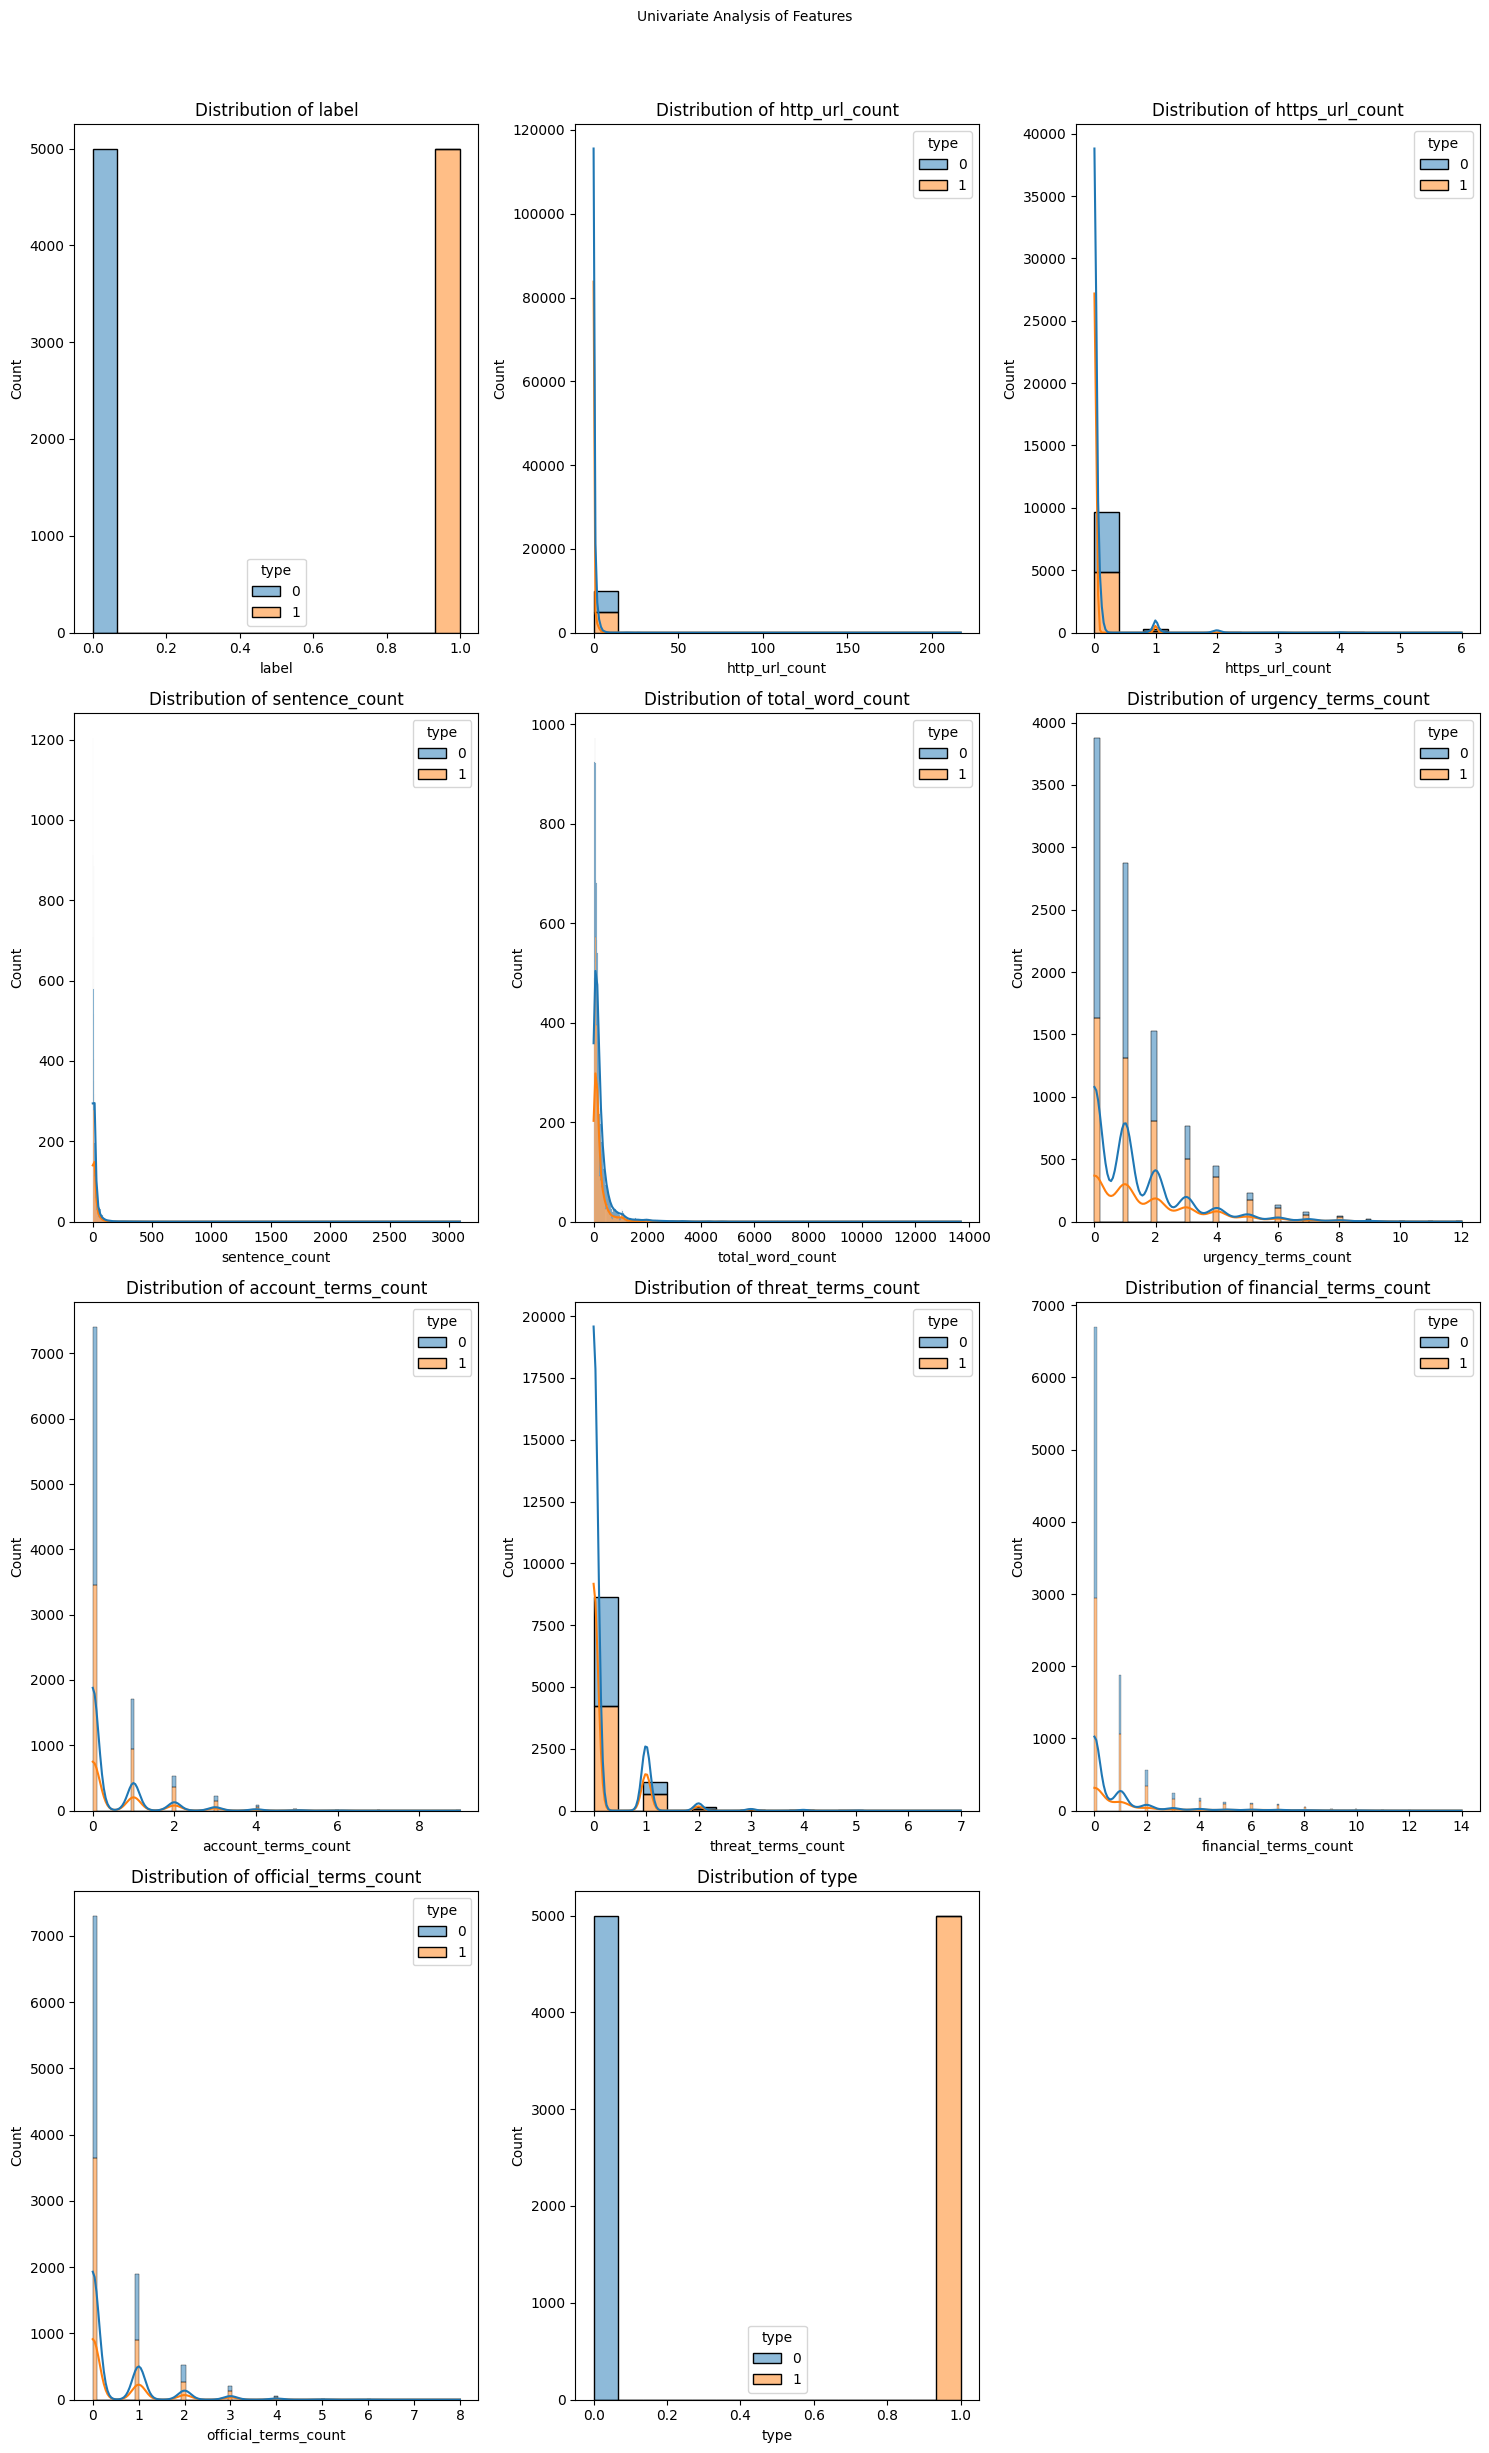

In [110]:

#generate the graphs for Univariate analysis for the whole then use df but we will use sample
analyze_phishing_email_Univariate_data(sampled_phishing_email_df)

### Multivariate analysis


Performing Bivariate Analysis...


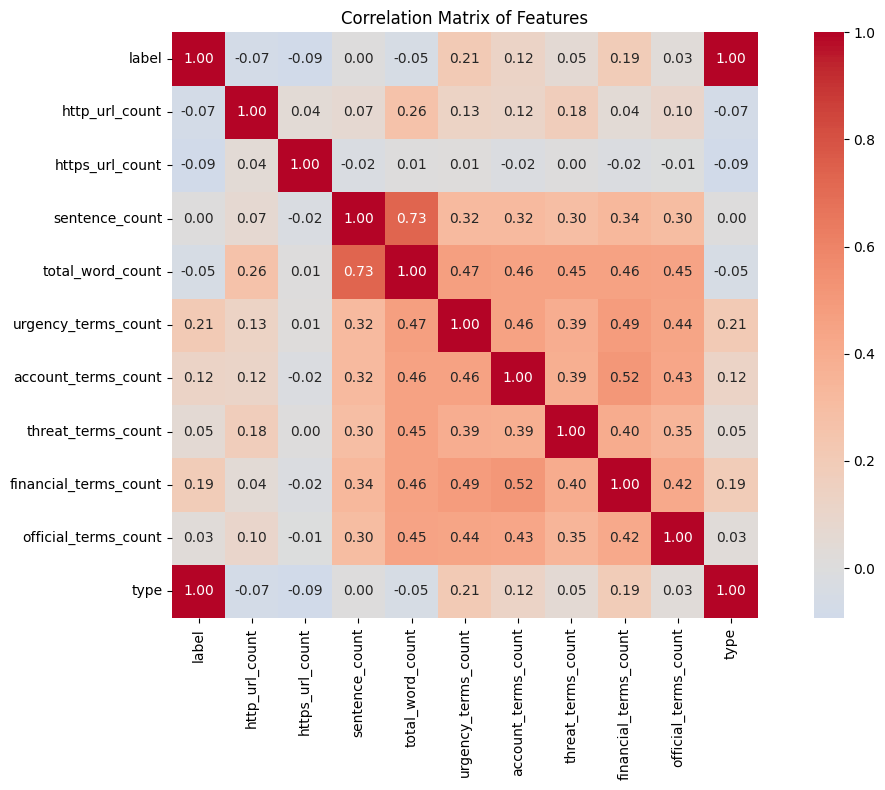

generating pairplot ...


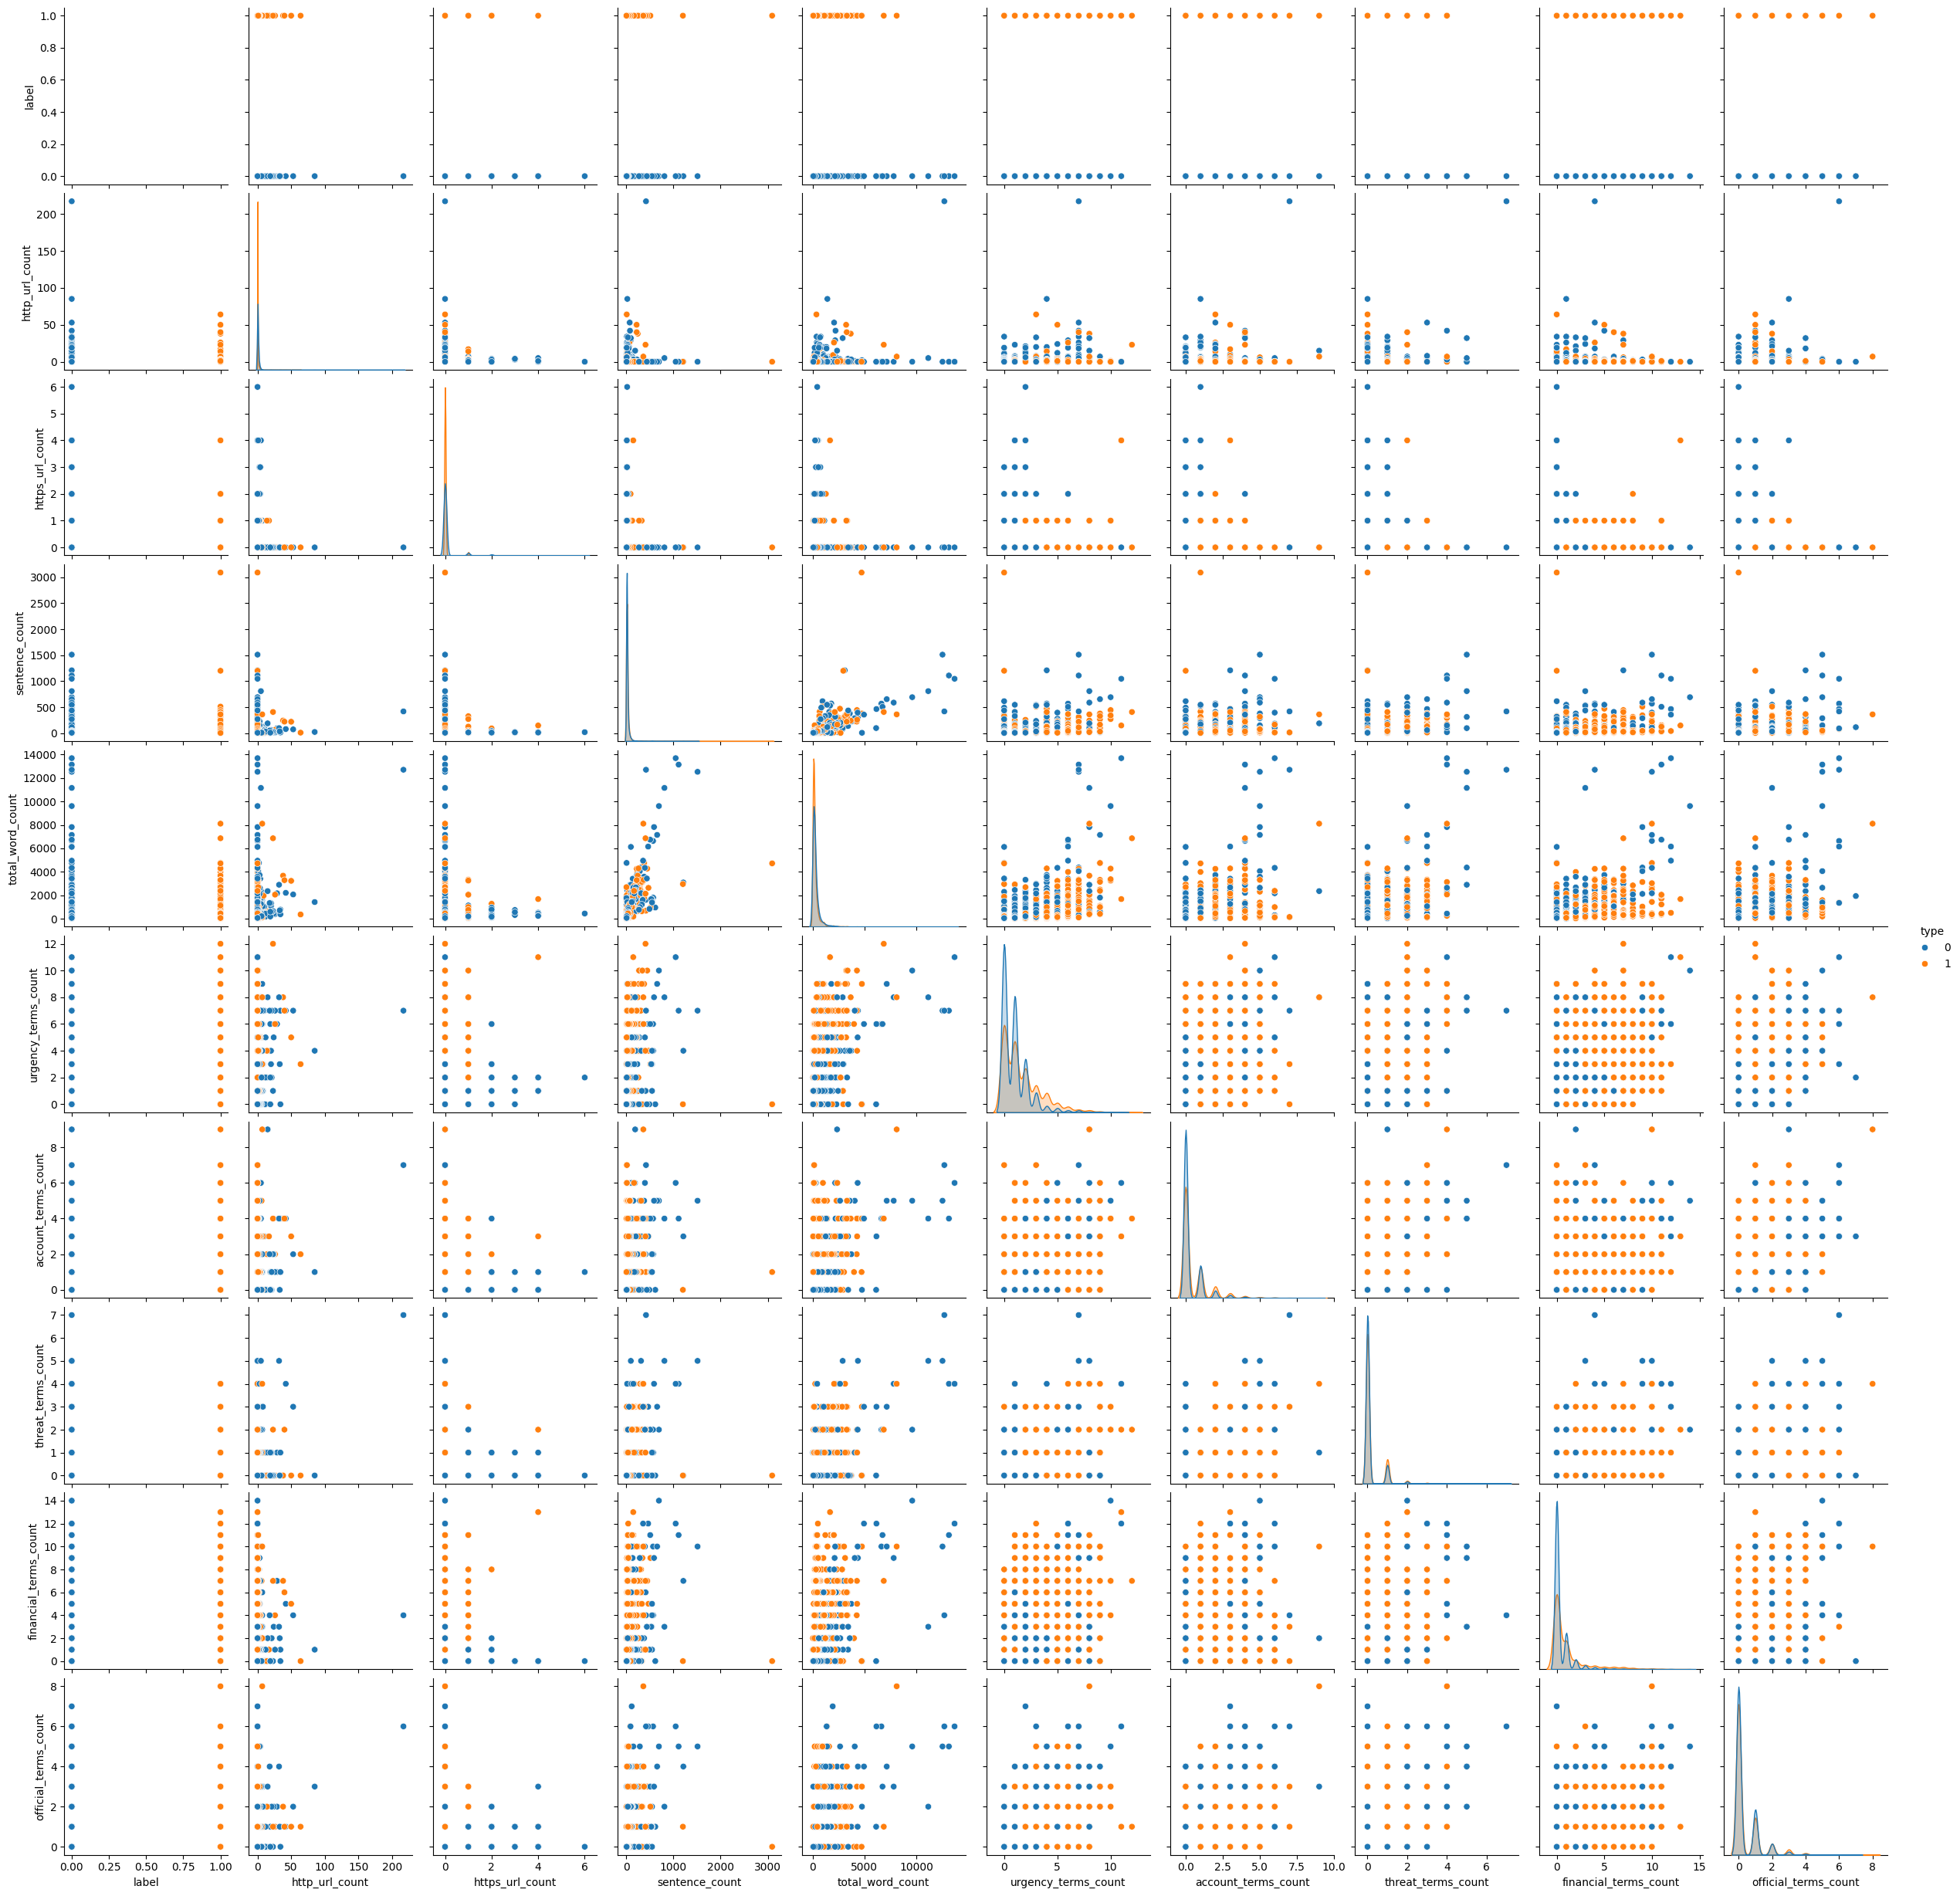

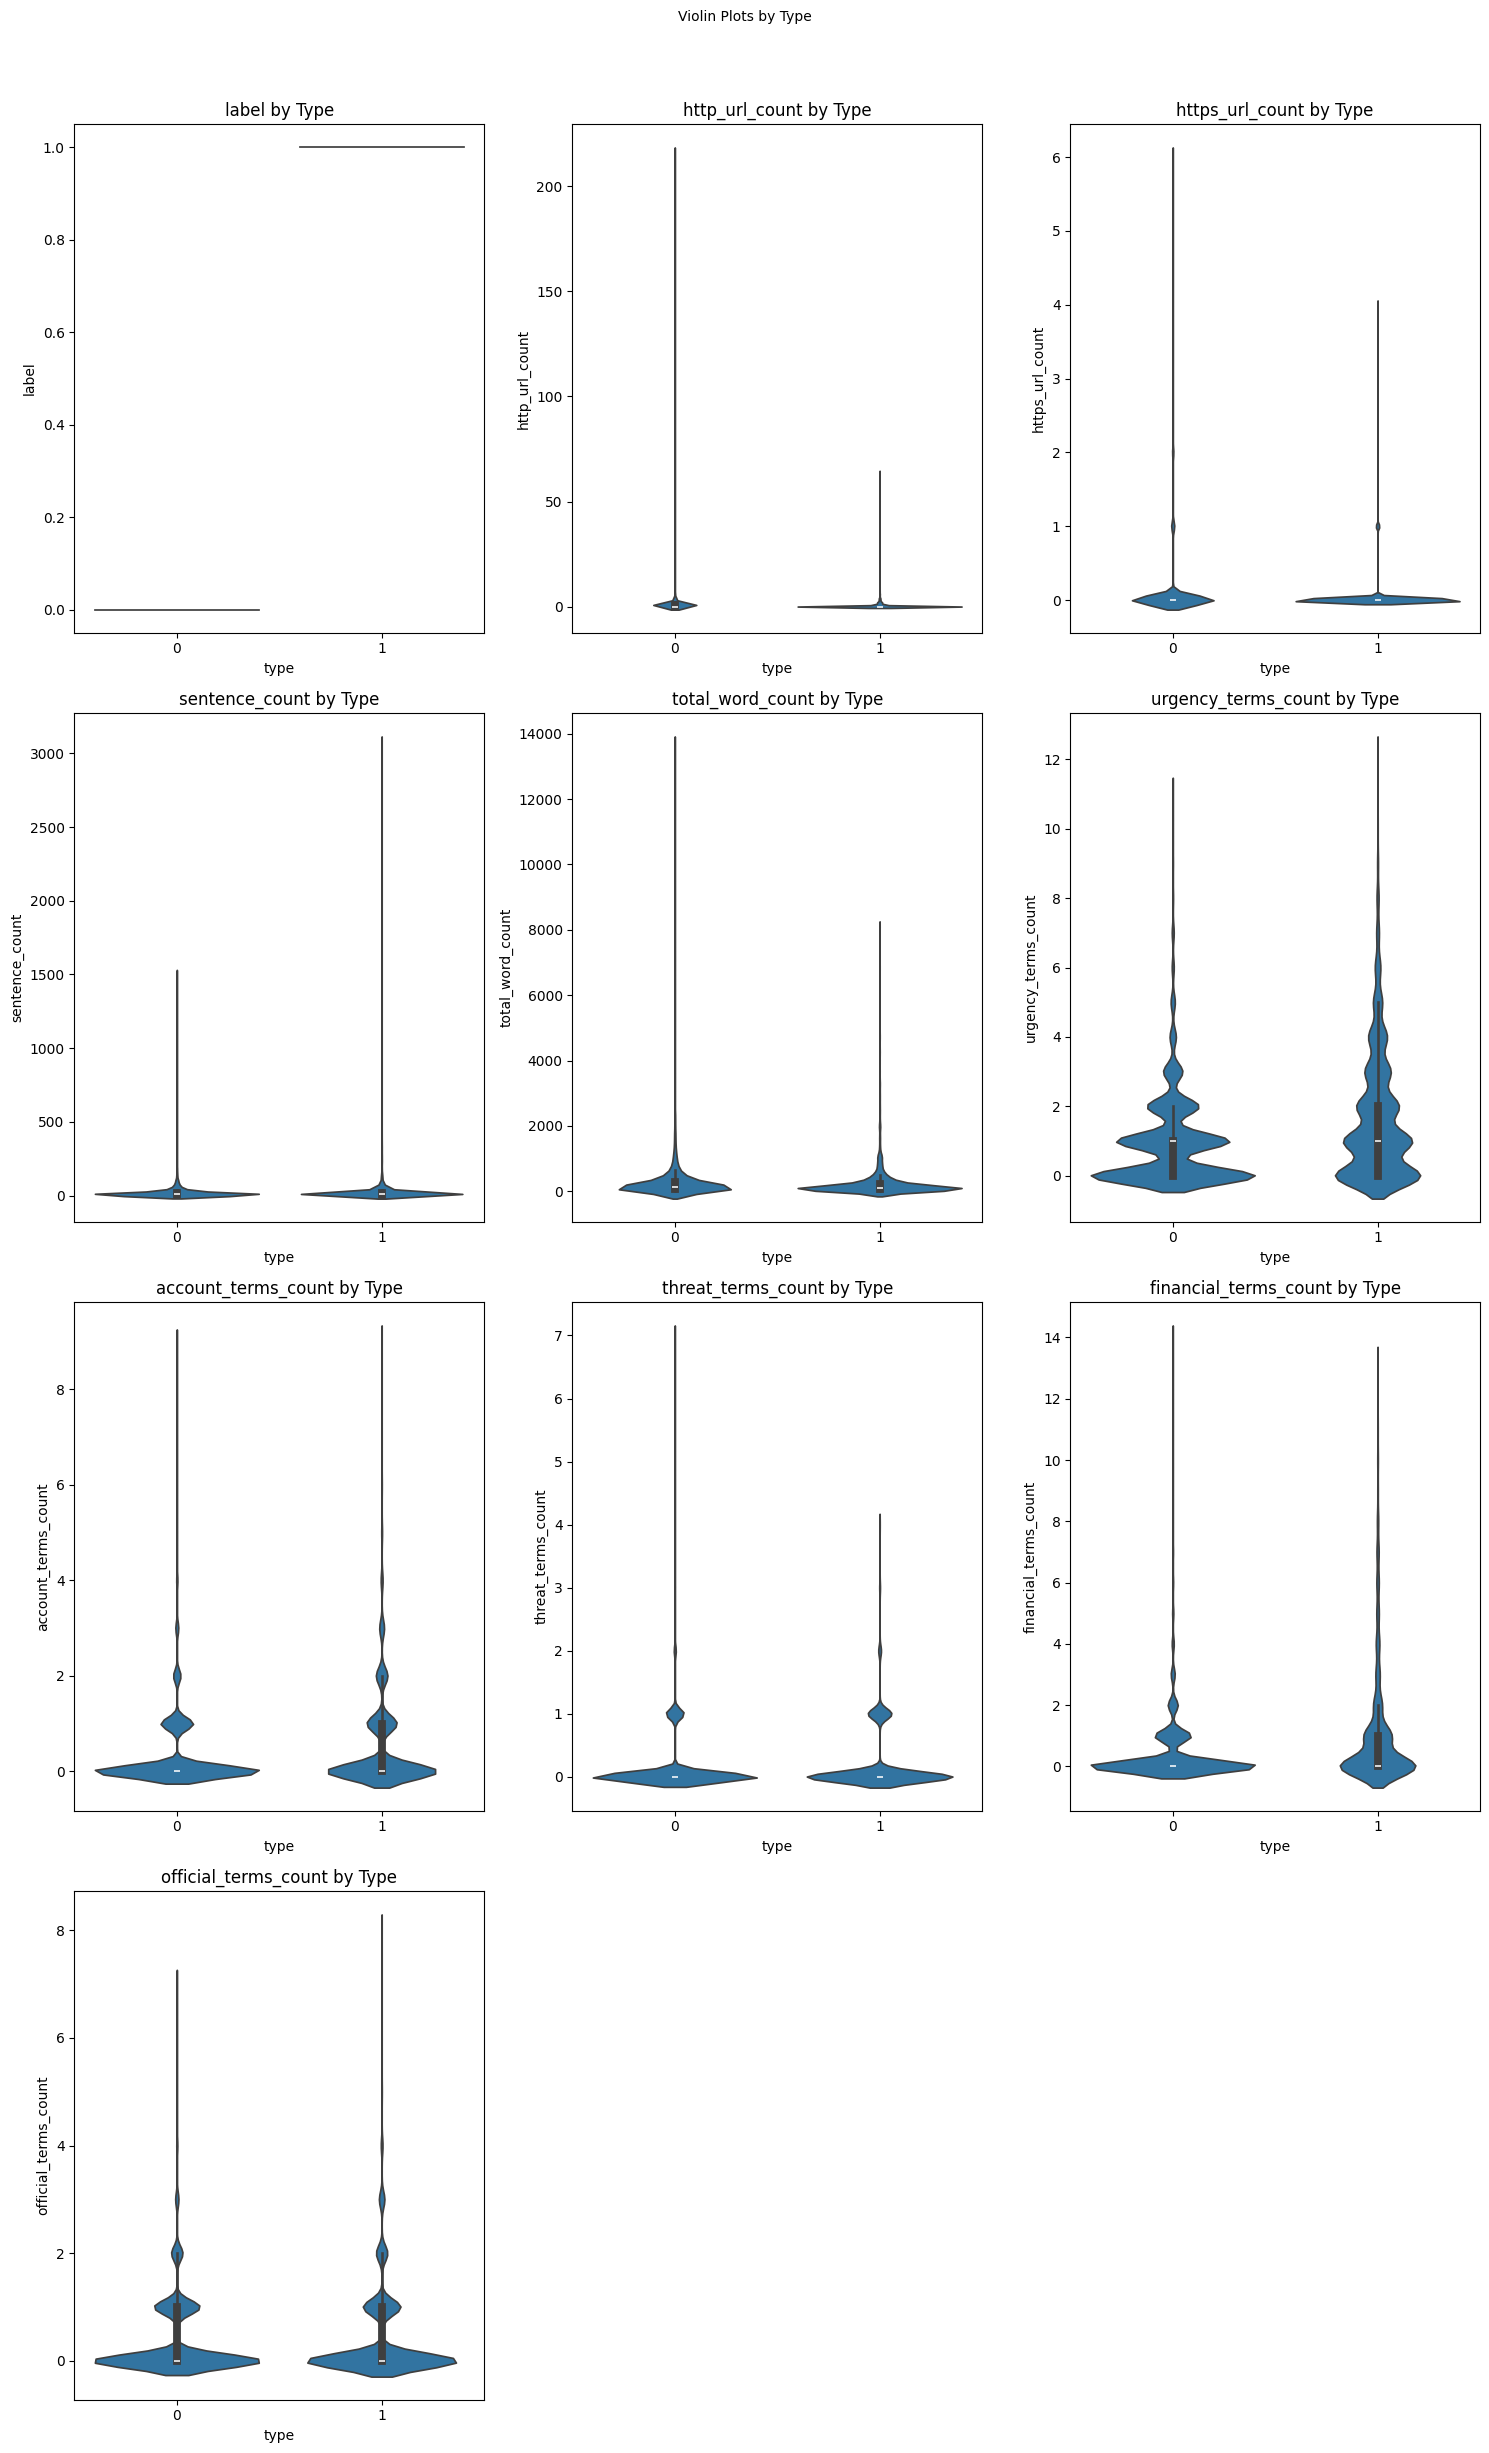

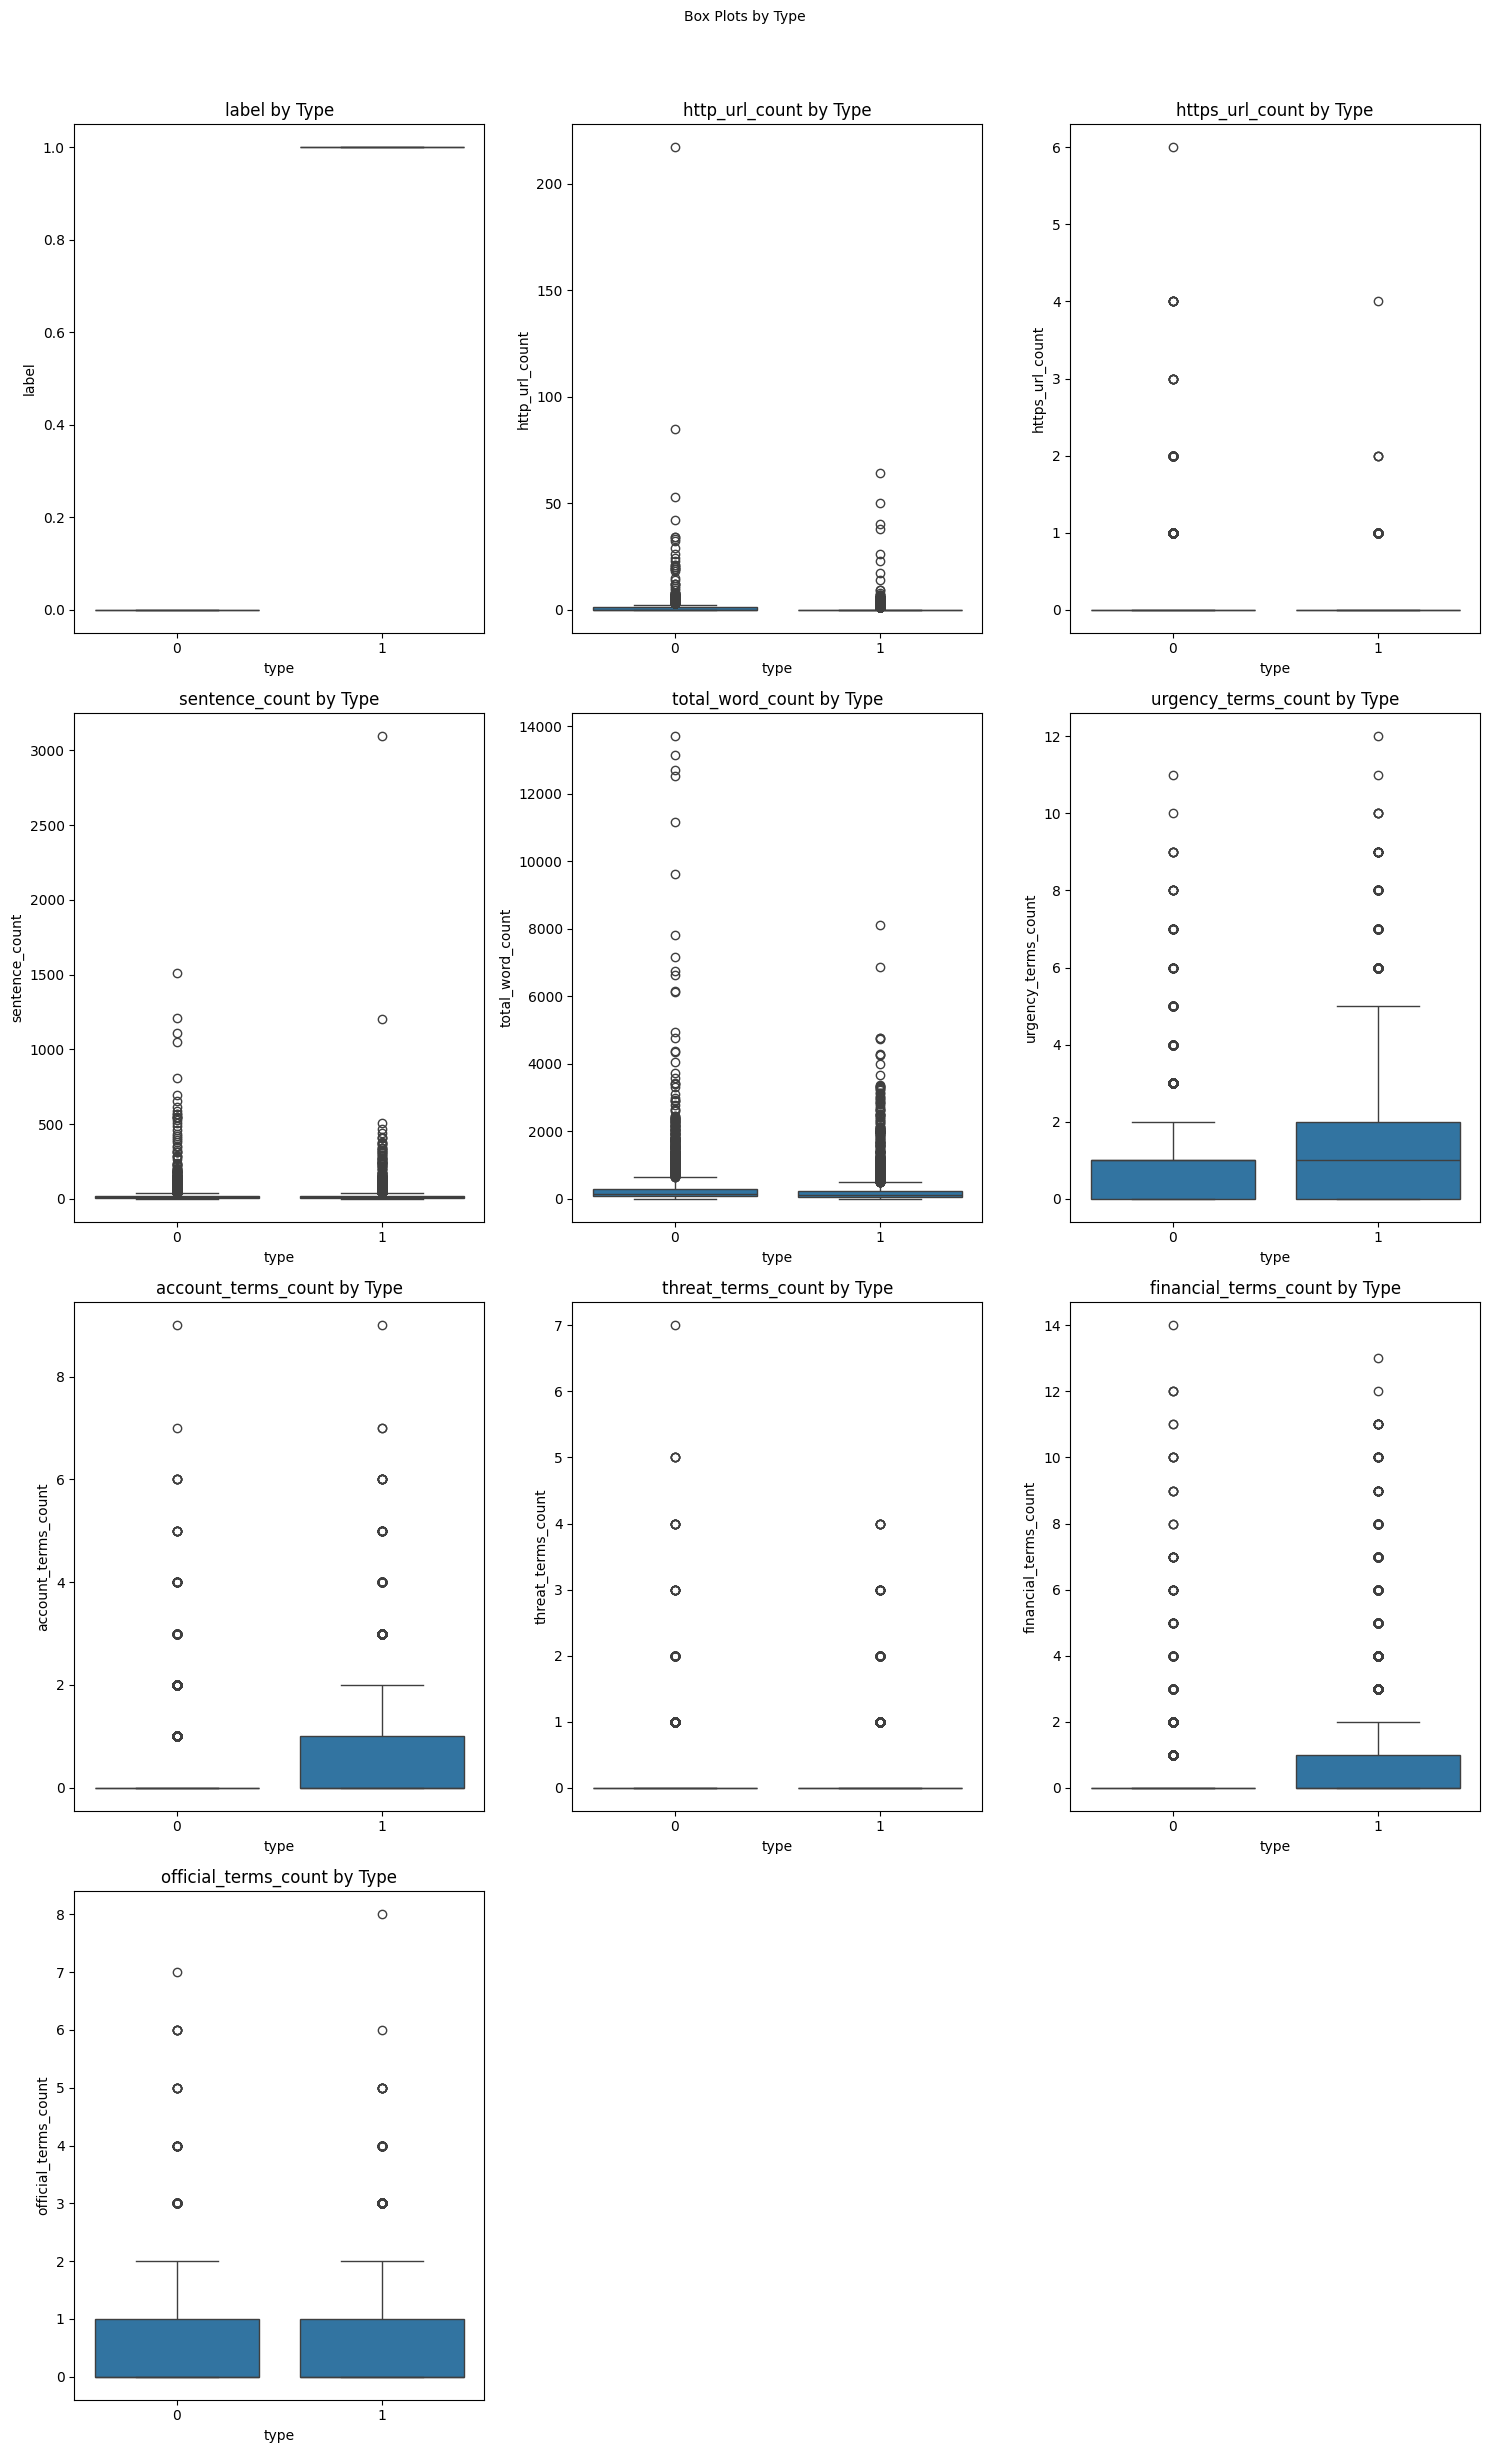


Performing KDE Analysis...


/var/folders/bm/9gklnwns2kxcypy3sp68vlc80000gn/T/ipykernel_90470/1777294569.py:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=df, x=feature, hue='type', ax=axes[idx])


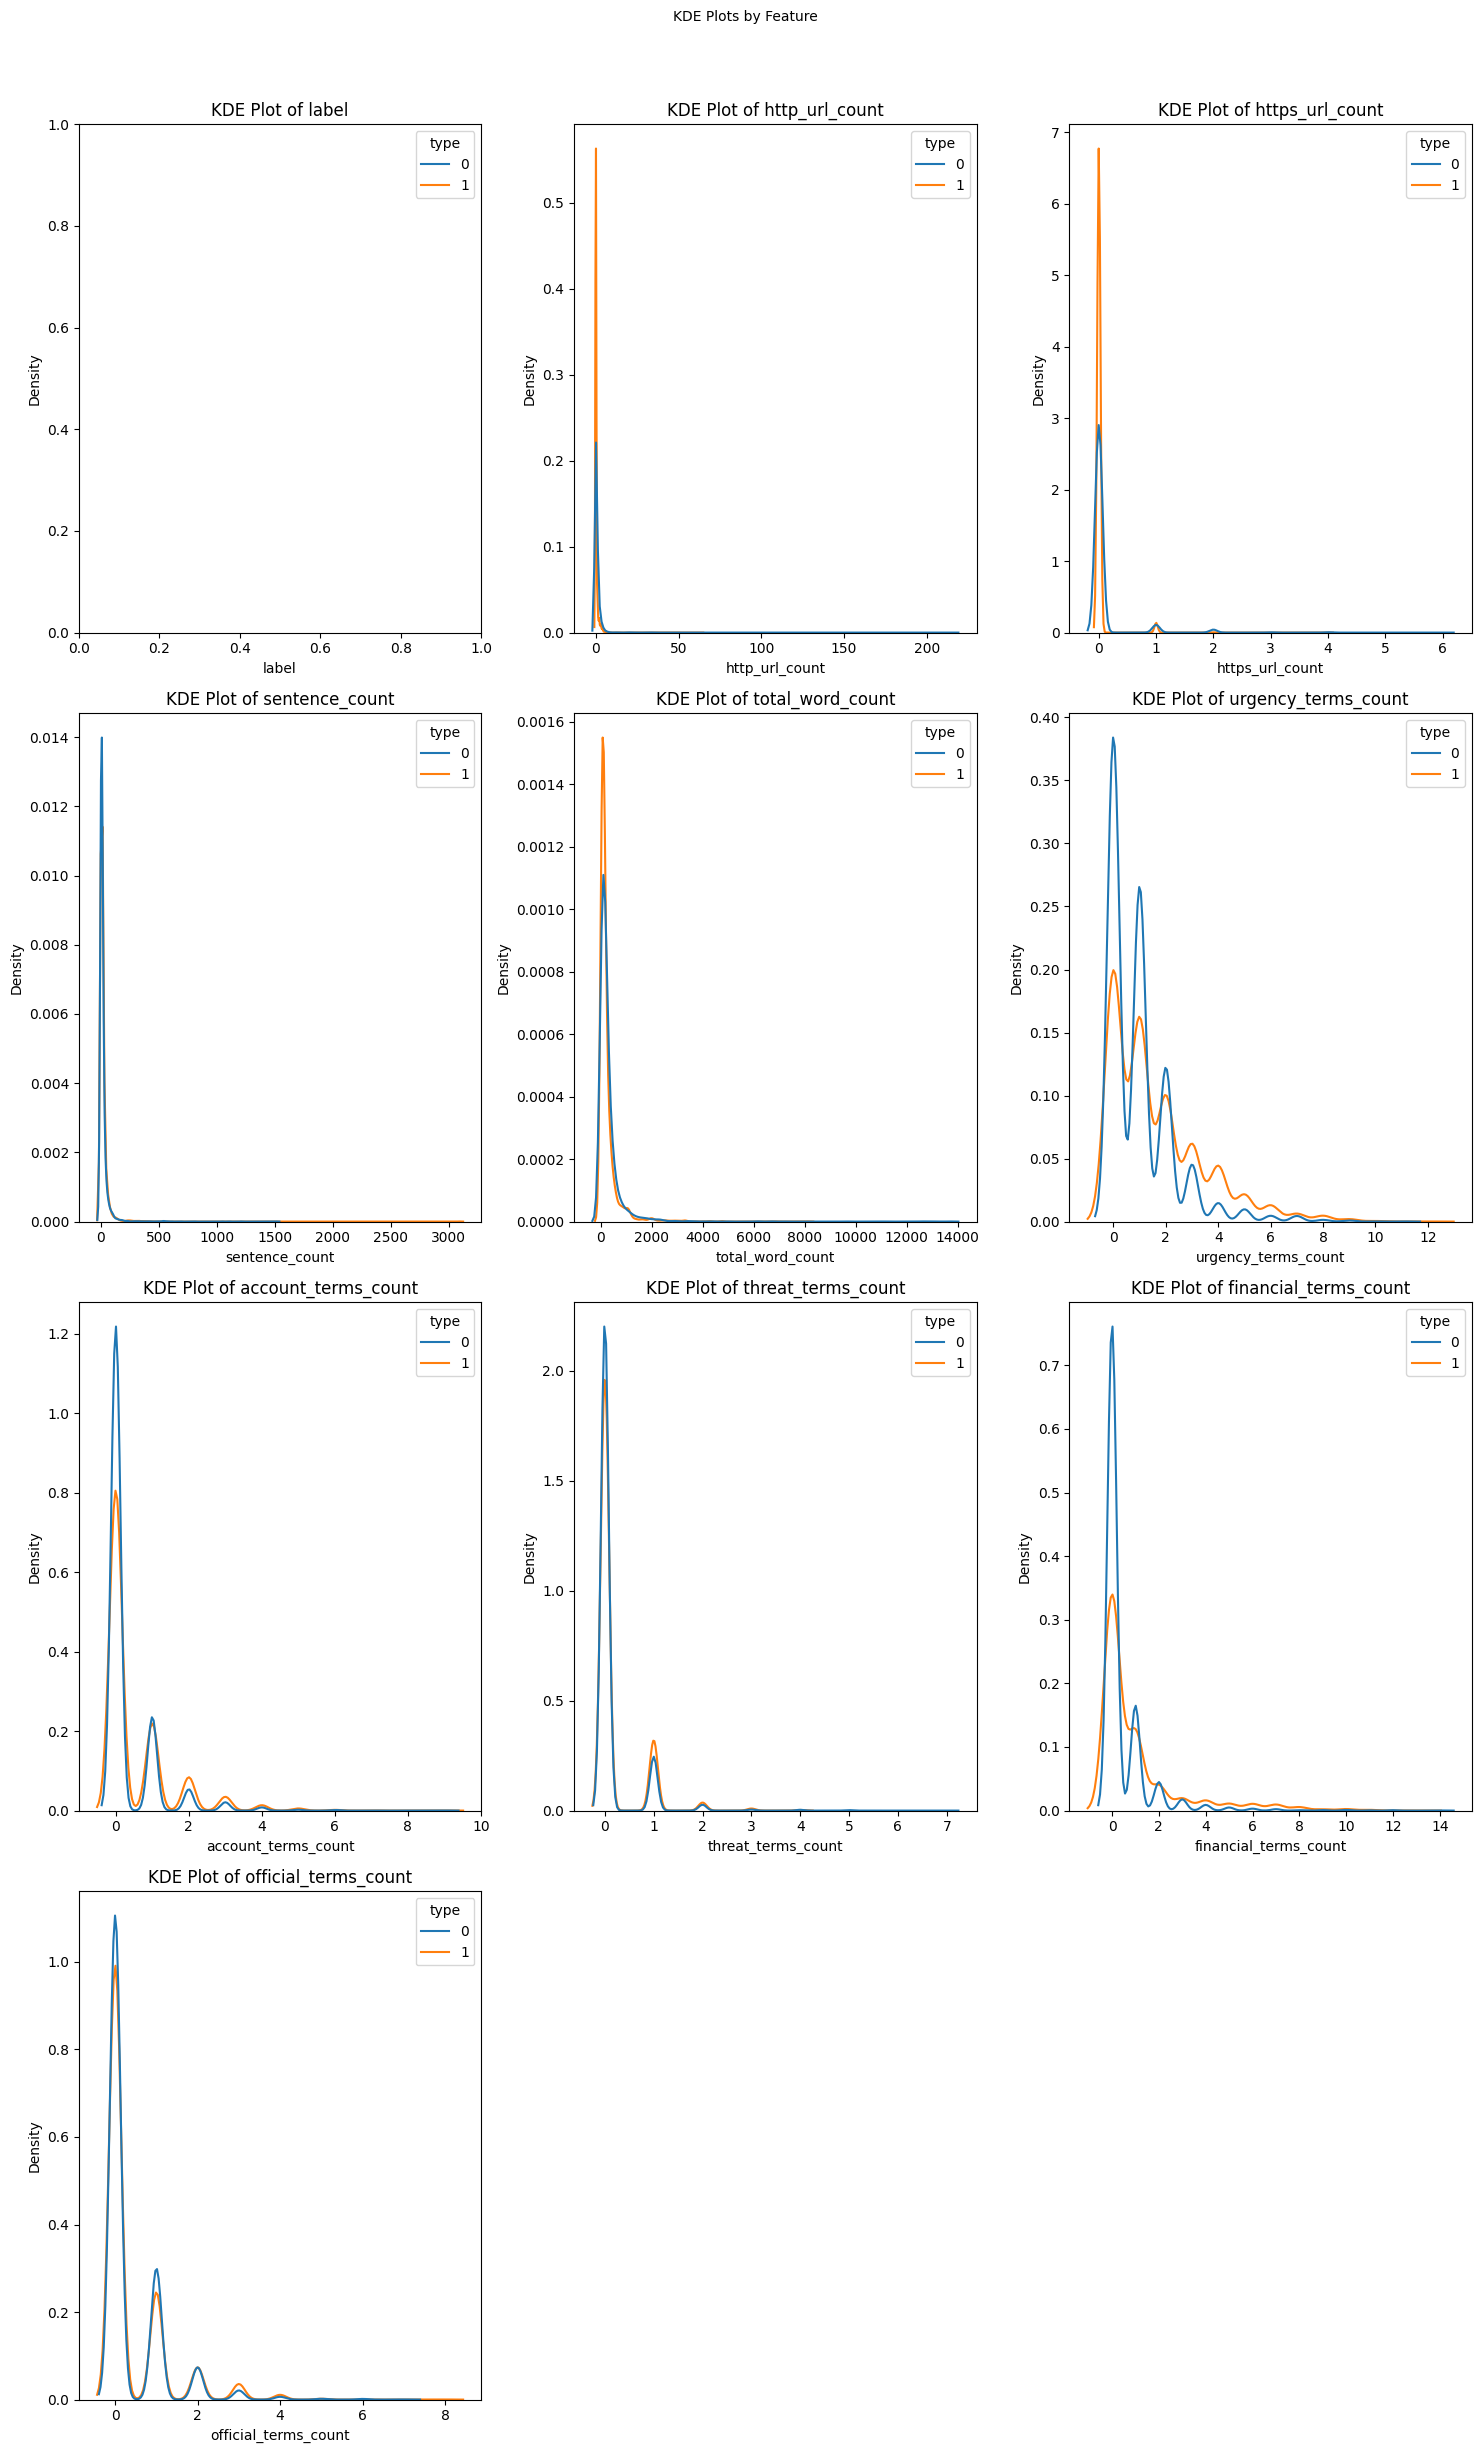

In [111]:

#generate the graphs for Biivariate analysis for the whole then use df but we will use sample
analyze_phishing_email_Bivariate_data(sampled_phishing_email_df)

In [112]:

if "label" not in df_phishing_email.columns:
    raise ValueError(
        "df_phishing_email does not contain a 'label' column."
    )

# ------------------------------------------------------------
# Display up to three random rows for each label value
# ------------------------------------------------------------
sampled_groups = []

print("=" * 80)
print("Random samples from df_phishing_email")

for label_value in sorted(
    df_phishing_email["label"].dropna().unique()
):
    label_group = df_phishing_email.loc[
        df_phishing_email["label"] == label_value
    ]

    selected_rows = label_group.sample(
        n=min(3, len(label_group)),
        replace=False,
    )

    print(
        f"\nLabel: {label_value}"
        f" | Available: {len(label_group):,}"
        f" | Displaying: {len(selected_rows)}"
    )

    display(selected_rows)
    sampled_groups.append(selected_rows)

# Include missing-label rows, if present
missing_label_group = df_phishing_email[
    df_phishing_email["label"].isna()
]

if not missing_label_group.empty:
    selected_rows = missing_label_group.sample(
        n=min(3, len(missing_label_group)),
        replace=False,
    )

    print(
        f"\nLabel: Missing"
        f" | Available: {len(missing_label_group):,}"
        f" | Displaying: {len(selected_rows)}"
    )

    display(selected_rows)
    sampled_groups.append(selected_rows)

# Store all displayed samples in one DataFrame
sampled_df_phishing_email = (
    pd.concat(
        sampled_groups,
        ignore_index=True,
    )
    if sampled_groups
    else df_phishing_email.iloc[0:0].copy()
)

# ------------------------------------------------------------
# Display label counts and dtype
# ------------------------------------------------------------
label_counts_by_dataframe = []

label_dtype = str(
    df_phishing_email["label"].dtype
)

counts = (
    df_phishing_email["label"]
    .value_counts(
        dropna=False
    )
    .sort_index(
        na_position="last"
    )
)

for label_value, record_count in counts.items():
    label_counts_by_dataframe.append(
        {
            "dataframe": "df_phishing_email",
            "label": label_value,
            "label_dtype": label_dtype,
            "records": record_count,
        }
    )

label_counts_df = pd.DataFrame(
    label_counts_by_dataframe
)

print("\nLabel distribution:")

display(
    label_counts_df.reset_index(
        drop=True
    )
)

Random samples from df_phishing_email

Label: 0 | Available: 10,980 | Displaying: 3


,label,http_url_count,https_url_count,sentence_count,total_word_count,urgency_terms_count,account_terms_count,threat_terms_count,financial_terms_count,official_terms_count
8201,0,0,0,7,50,1,0,0,0,0
17477,0,0,0,20,267,1,0,0,0,0
11102,0,0,0,2,50,0,0,0,0,1



Label: 1 | Available: 6,557 | Displaying: 3


,label,http_url_count,https_url_count,sentence_count,total_word_count,urgency_terms_count,account_terms_count,threat_terms_count,financial_terms_count,official_terms_count
7121,1,0,0,1,39,0,0,0,0,0
10893,1,0,0,32,638,4,4,0,0,1
13185,1,0,0,16,173,1,0,0,1,0



Label distribution:


,dataframe,label,label_dtype,records
0,df_phishing_email,0,int64,10980
1,df_phishing_email,1,int64,6557


#### Data prep complete 


In [114]:
print(f"Combined dataset columns: {df_combined.columns}" )
df_combined.shape

Combined dataset columns: Index(['text_combined', 'label'], dtype='object')


(17537, 2)

In [115]:
df_combined.shape

(17537, 2)

In [116]:
df_combined.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17537 entries, 0 to 17536
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text_combined  17537 non-null  object
 1   label          17537 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 274.1+ KB


In [117]:


"""Nine count features and a TF-IDF comparison for Phishing_email dataset.

We are using a numeric label 0=legitimate, 1=phishing.  

"""

TOKEN_PATTERN = r"(?u)\b[^\W\d_]+(?:'[^\W\d_]+)*\b"


WORD_RE = re.compile(TOKEN_PATTERN)


URL_RE = re.compile(r"\b(?:https?://|www\.)[^\s<>\"']+", re.I)


EMAIL_RE = re.compile(r"\b[^\s<>@]+@[^\s<>@]+\.[^\s<>@]+\b")


TERM_CATEGORIES = {
    "urgency": {
        "urgent", "immediate", "immediately", "action required", "attention required", "respond now",
        "expires", "expiring", "deadline", "limited time", "act now", "urgent action", "click",
        "here", "now", "free", "offer", "buy", "purchase", "donate", "subscribe", "register",
        "sign up", "get started", "learn more",
    },
    "account": {
        "verify", "verification", "authenticate", "confirm", "validate", "reactivate",
        "suspended", "blocked", "restricted", "limited", "unlock", "secure", "security",
        "access", "password", "login", "account", "username", "credential",
    },
    "threat": {
        "terminate", "deactivate", "delete", "removal", "suspend", "restriction",
        "warning", "risk", "compromised", "suspicious", "unauthorized", "disabled",
        "cancelled", "violation", "breach", "illegal",
    },
    "financial": {
        "claim", "prize", "winner", "won", "reward", "bonus", "payment", "refund",
        "deposit", "transfer", "transaction", "million", "inheritance", "lottery",
        "cash", "credit", "bank", "money", "fund", "balance",
    },
    "official": {
        "official", "authorized", "authentication", "notification", "notice", "alert",
        "department", "administration", "support", "service", "helpdesk",
    },
}


# Rest of this cell is the text prep section  
# create a html parser to extract visible text from HTML content, ignoring script and style tags
 

class _VisibleText(HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []
        self.suppressed = 0

    def handle_starttag(self, tag, attrs):
        if tag in {"script", "style"}:
            self.suppressed += 1

    def handle_endtag(self, tag):
        if tag in {"script", "style"} and self.suppressed:
            self.suppressed -= 1

    def handle_data(self, data):
        if not self.suppressed:
            self.parts.append(data)


def visible_email_text(value):
    """Extract visible text while preserving case and sentence punctuation."""
    if pd.isna(value):
        return ""
    text = str(value)
    if re.search(r"</?[A-Za-z][^>]*>", text):
        parser = _VisibleText()
        parser.feed(text)
        text = " ".join(parser.parts)
    return html.unescape(text).replace("\u2019", "'")


def clean_email_text(value):
    """Basic word-only view; keep the original text separately for URL features.

    Does not decode MIME/base64/quoted-printable or recover previously removed URLs.
    Preserves apostrophes/negation and word order; removes tags, URLs and addresses.
    """
    text = visible_email_text(value).casefold()
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    return " ".join(WORD_RE.findall(text))



In [ ]:
COUNT_FEATURE_COLUMNS = [
    "http_url_count", "https_url_count", "sentence_count", "total_word_count",
    "urgency_terms_count", "account_terms_count", "threat_terms_count",
    "financial_terms_count", "official_terms_count",
]

# Hash a string using SHA-256 to group identical text entries or near similar text for cross-validation splitting. This is used to avoid data leakage between training and validation sets.
def _hash(value):
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

# Create a list of all the count features

def prepare_email_corpus(frame, text_column="text_combined", label_column="label"):
    """Return (model_corpus, audit). Do not mutate the input frame.

    Exact deduplication ignores whitespace differences only. Conflicting labels
    for the same exact text are set aside. Broader normalized matches are grouped
    for splitting, not silently deleted or relabeled.
    """
    
    #  INPUT VALIDATION & INITIAL COPYING
    
    # Ensure required text and target label columns exist in the DataFrame.
    if not {text_column, label_column}.issubset(frame.columns):
        raise ValueError(f"Expected columns {text_column!r} and {label_column!r}.")

    # Work on a defensive shallow copy to avoid mutating the user's original DataFrame.
    data = frame.copy().reset_index(drop=True)

    # Track 1-based original row numbers for debugging and audit logs.
    data["input_row"] = np.arange(1, len(data) + 1)

    # Standardize missing text entries to empty strings and cast to string data type.
    data["text"] = data[text_column].fillna("").astype(str)

    # Parse labels into numeric values, raising errors on non-numeric entries.
    target = pd.to_numeric(data[label_column], errors="raise")

    # Validate that non-null labels are strictly binary (0 or 1).
    if not target.dropna().isin([0, 1]).all():
        raise ValueError("Labels must be 0 or 1; missing labels will be excluded.")

    # Cast to pandas' nullable integer type 'Int64' to keep missing labels as NaNs safely.
    data["label"] = target.astype("Int64")

   
    # FILTERING MISSING LABELS & EMPTY TEXT
   
    # Extract records with missing target labels into the audit log, then keep valid rows.
    missing_labels = data[data["label"].isna()].copy()
    data = data[data["label"].notna()].copy()

    # Collapse multi-whitespace sequences and trim padding for baseline deduplication.
    exact = data["text"].str.replace(r"\s+", " ", regex=True).str.strip()

    # Clean text (e.g., removing stop words, HTML, or special characters) for grouping.
    data["word_text"] = data["text"].map(clean_email_text)

    # Flag rows that are blank, labeled explicitly as "empty", or empty after word cleaning.
    empty_mask = exact.str.casefold().isin(["", "empty"]) | data["word_text"].eq("")
    empty_records = data[empty_mask].copy()
    data = data[~empty_mask].copy()

    # Hash the whitespace-normalized exact text for precise content tracking.
    data["content_hash"] = exact.loc[data.index].map(_hash)

    
    # CONFLICT RESOLUTION & DEDUPLICATION
    
    # Identify hashes that correspond to multiple unique target labels (label noise/conflicts).
    counts = data.groupby("content_hash")["label"].nunique()
    conflicts = data[data["content_hash"].isin(counts.index[counts > 1])].copy()
    consistent = data[~data["content_hash"].isin(counts.index[counts > 1])].copy()

    # Calculate duplicate frequencies and separate secondary copies for auditing.
    copies = consistent.groupby("content_hash").size()
    duplicates = consistent[consistent.duplicated("content_hash", keep="first")].copy()

    # Retain only the first occurrence of each unique text string.
    corpus = consistent.drop_duplicates("content_hash", keep="first").copy()
    corpus["copies"] = corpus["content_hash"].map(copies)

    # Combine all distinct file sources associated with each unique message if available.
    if "source_file" in consistent:
        sources = consistent.groupby("content_hash")["source_file"].agg(
            lambda s: " | ".join(sorted(set(s.dropna().astype(str))))
        )
        corpus["sources"] = corpus["content_hash"].map(sources)

   
    #  CROSS-VALIDATION SPLITING GROUPS & INTEGRITY CHECKS
    
    def split_key(text):
        """Generates a group hash to prevent data leakage during CV splits."""
        words = text.split()
        reduced = [w for w in words if w not in ENGLISH_STOP_WORDS]
        # Keep short texts specific rather than group all generic short messages.
        return _hash(" ".join(reduced if len(reduced) >= 8 else words))

    # Map split keys to ensure similar emails are kept in the same CV partition/fold.
    corpus["group_id"] = corpus["word_text"].map(split_key)

    # Final label type formatting and index reset.
    corpus["label"] = corpus["label"].astype("int64")
    corpus = corpus.reset_index(drop=True)

    # Verify that both classes (0 and 1) are present after all filtering steps.
    if corpus["label"].nunique() != 2:
        raise ValueError("Both classes are required after cleaning.")

    
    #  AUDIT LOG ASSEMBLY & RETURN
    
    audit = {
        "summary": pd.Series({
            "input_rows": len(frame),
            "missing_label_rows": len(missing_labels),
            "empty_word_text_rows": len(empty_records),
            "conflicting_label_rows": len(conflicts),
            "duplicate_copies_removed": len(duplicates),
            "usable_rows": len(corpus),
            "split_groups": corpus["group_id"].nunique(),
        }, name="rows"),
        "missing_labels": missing_labels,
        "empty_records": empty_records,
        "label_conflicts": conflicts,
        "duplicate_copies": duplicates,
    }

    return corpus, audit

In [ ]:
def split_email_corpus(corpus, holdout_folds=5, cv_folds=3, random_state=42):
    """Approx. 1/holdout_folds held out; groups cannot cross holdout/CV splits."""
    
    
    #  HOLDOUT SPLIT VALIDATION
    
    # Ensure every target class has enough distinct groups to be distributed
    # across the requested number of holdout folds.
    if corpus.groupby("label")["group_id"].nunique().min() < holdout_folds:
        raise ValueError("Too few distinct groups per class for the requested holdout split.")

    
    #  HOLDOUT (TEST SET) CREATION
    
    # Instantiate a stratified group k-fold splitter to maintain class balances
    # while keeping identical group_ids within the same partition.
    splitter = StratifiedGroupKFold(
        n_splits=holdout_folds, shuffle=True, random_state=random_state
    )

    # Extract the first fold to serve as the holdout (test) split.
    train_idx, test_idx = next(splitter.split(corpus["text"], corpus["label"], corpus["group_id"]))
    
    # Slice the original corpus into training and test datasets, resetting indices.
    train = corpus.iloc[train_idx].reset_index(drop=True)
    test = corpus.iloc[test_idx].reset_index(drop=True)

    # Ensure both target classes (0 and 1) exist in both train and test splits.
    if train["label"].nunique() != 2 or test["label"].nunique() != 2:
        raise ValueError("This grouped holdout lacks a class; reconsider the split configuration.")

    
    # CROSS-VALIDATION (CV) SPLIT CREATION
    
    # Validate that the training partition contains enough unique groups per class for CV.
    if train.groupby("label")["group_id"].nunique().min() < cv_folds:
        raise ValueError("Too few training groups per class for CV.")

    # Configure a secondary StratifiedGroupKFold splitter for inner cross-validation.
    cv = StratifiedGroupKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    splits = list(cv.split(train["text"], train["label"], train["group_id"]))

   
    # CV FOLD INTEGRITY CHECKS
    
    # Verify that every individual fit/validation fold pair contains both classes.
    for fit_idx, valid_idx in splits:
        if any(train.iloc[idx]["label"].nunique() != 2 for idx in (fit_idx, valid_idx)):
            raise ValueError("A grouped CV fold lacks a class; reconsider the split configuration.")

    return train, test, splits

In [ ]:
EMAIL_STOP_WORDS = {
    "subject", "from", "to", "cc", "bcc", "sent", "received", "date", "time",
    "regards", "dear", "sincerely", "best", "thanks", "thank", "you", "yours",
    "truly", "hi", "hello",
}


def extract_count_features(texts, stop_words=None, sentence_tokenizer=None):
    """Return (nine integer features, stop-word-filtered text).

    General stop words are removed, but all words occurring in a fixed category
    term/phrase and common negations are protected. Repeated/overlapping terms
    count separately. Phrases must be contiguous in the original word sequence;
    removing stop words cannot manufacture a new phrase match.

    total_word_count counts remaining alphabetic/apostrophe-containing tokens,
    excluding URLs/addresses/numerals/punctuation. URL counts are raw occurrences,
    including HTML attributes, not unique destinations. Sentence counting uses
    visible text with URLs/addresses removed, before stop-word filtering.
    clean_text is retained for the later TF-IDF comparison.
    """
    
    # INITIALIZATION & DEPENDENCY CHECKS
    
    # Default to standard NLTK English stop words if none are supplied.
    if stop_words is None:
        from nltk.corpus import stopwords
        stop_words = set(stopwords.words("english"))
        
    # Default to standard NLTK sentence tokenizer if none is supplied.
    if sentence_tokenizer is None:
        from nltk.tokenize import sent_tokenize
        sentence_tokenizer = sent_tokenize
        
    # Validation step: Test tokenizer immediately to fail fast if NLTK resources are missing.
    sentence_tokenizer("Tokenizer check.")

    
    # CATEGORY TERM PREPARATION & STOP-WORD PROTECTION
    
    # Tokenize and clean category search terms defined in TERM_CATEGORIES.
    terms = {name: [tuple(clean_email_text(t).split()) for t in sorted(values)]
             for name, values in TERM_CATEGORIES.items()}
    
    # Identify words that must NOT be stripped as stop words (e.g., words inside phrase terms).
    protected = {w for category in terms.values() for term in category for w in term}
    
    # Protect common negation words so key sentiment signals are preserved.
    protected.update({"no", "not", "nor", "never", "cannot", "don't", "doesn't", "isn't", "won't"})
    protected.update(w for w in stop_words if w.endswith("n't"))
    
    # Construct final effective stop-word set excluding protected terms.
    effective_stop_words = (set(stop_words) | EMAIL_STOP_WORDS) - protected
    
    # Find the maximum n-gram word length across all defined category phrases.
    max_n = max(len(term) for category in terms.values() for term in category)

    # Standardize input strings into a clean pandas Series.
    raw = texts.fillna("").astype(str) if isinstance(texts, pd.Series) else pd.Series(texts).fillna("").astype(str)
    records, cleaned = [], []

   
    #  FEATURE EXTRACTION LOOP
   
    for text in raw:
        # Tokenize and clean email text while preserving word positional indices.
        words = clean_email_text(text).split()
        kept = [(i, w) for i, w in enumerate(words) if w not in effective_stop_words]
        filtered = [w for _, w in kept]
        cleaned.append(" ".join(filtered))

        # Count individual unigrams from filtered words.
        occurrences = Counter((w,) for w in filtered)
        
        # Count contiguous n-grams (phrases) that were strictly contiguous in the original text.
        for n in range(2, max_n + 1):
            for i in range(len(kept) - n + 1):
                window = kept[i:i+n]
                # Check original indices: index difference of (n-1) guarantees contiguous sequence.
                if window[-1][0] - window[0][0] == n - 1:
                    occurrences[tuple(w for _, w in window)] += 1

        # Strip URLs/email addresses to isolate human-readable text for sentence counting.
        visible = EMAIL_RE.sub(" ", URL_RE.sub(" ", visible_email_text(text))).strip()
        
        # Compile core structural and link count features.
        record = {
            "http_url_count": len(re.findall(r"\bhttp://[^\s<>\"']+", text, re.I)),
            "https_url_count": len(re.findall(r"\bhttps://[^\s<>\"']+", text, re.I)),
            "sentence_count": len(sentence_tokenizer(visible)) if visible else 0,
            "total_word_count": len(filtered),
        }
        
        # Sum keyword/phrase occurrences for each predefined category (e.g., urgency, financial).
        record.update({f"{name}_terms_count": sum(occurrences[t] for t in category)
                       for name, category in terms.items()})
        records.append(record)

    
    # OUTPUT ASSEMBLY
    
    # Format structural and term features into a 64-bit integer DataFrame.
    features = pd.DataFrame(records, columns=COUNT_FEATURE_COLUMNS, index=raw.index).astype("int64")
    
    # Return numerical features along with the cleaned text series for downstream TF-IDF tasks.
    return features, pd.Series(cleaned, index=raw.index, name="clean_text")


def prepare_count_dataset(frame, stop_words=None, sentence_tokenizer=None):
    """Keep raw text/metadata, add nine features and cleaned text, return audit.

    Input columns: text_combined and label. Uses no learned word vocabulary or
    label-based feature selection, so fixed extraction can precede the split.
    """
    corpus, audit = prepare_email_corpus(frame)
    features, cleaned = extract_count_features(corpus["text"], stop_words, sentence_tokenizer)
    # Re-running on a frame containing feature columns replaces them, not duplicates.
    corpus = corpus.drop(columns=COUNT_FEATURE_COLUMNS + ["clean_text"], errors="ignore")
    return pd.concat([corpus, features, cleaned], axis=1), audit

### Week 2 activities to do OLS regression using regularization terms of Lasso, Ridge and ElasticNet

In [121]:
def compare_regression_features(
    train,
    cv_splits,
    max_features=5000,
    min_df=5,
    n_jobs=2,
    max_iter=50000,
    feature_sets=(
        "Counts",
        "TF-IDF",
        "Counts + TF-IDF",
    ),
):
    """
    Tune Ridge, Lasso, and Elastic Net models.

    For every feature-set/model combination, this method records:

    - Cross-validation RMSE
    - Best alpha
    - Best Elastic Net l1_ratio
    - Number of non-zero coefficients
    - Complete GridSearchCV execution time
    - Whether alpha is at the edge of the search grid

    Fit_Time_Seconds includes all cross-validation fits, all
    hyperparameter combinations, and the final refit.
    
"""

    # Define the baseline columns we expect in the training data
    required_columns = (
        COUNT_FEATURE_COLUMNS
        + ["clean_text", "label"]
    )

    # We validate inputs early to fail fast if the dataset is malformed
    missing_columns = [
        column
        for column in required_columns
        if column not in train.columns
    ]

    if missing_columns:
        raise ValueError(
            "Training data is missing required columns: "
            f"{missing_columns}"
        )

    # I set up the model specifications alongside their specific hyperparameter grids
    specs = {
        "Ridge": (
            Ridge(
                solver="lsqr",
                tol=1e-5,
            ),
            {
                # L2 regularization strength
                "model__alpha": np.logspace(-2, 4, 7),
            },
        ),
        "Lasso": (
            Lasso(
                max_iter=max_iter,
                tol=1e-4,
                selection="cyclic",
            ),
            {
                # L1 regularization strength (usually requires smaller values)
                "model__alpha": np.logspace(-6, -2, 9),
            },
        ),
        "Elastic Net": (
            ElasticNet(
                max_iter=max_iter,
                tol=1e-4,
                selection="cyclic",
            ),
            {
                "model__alpha": np.logspace(-6, -2, 9),
                # Mix ratio between L1 and L2 penalties
                "model__l1_ratio": [
                    0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 0.99,
                ],
            },
        ),
    }

    searches = {}
    rows = []

    # We use a temporary directory so our cached files are automatically wiped after execution
    with TemporaryDirectory(
        prefix="phishing_feature_cv_"
    ) as cache:
        # Initialize the cache manager to prevent recalculating text features across CV folds
        memory = Memory(
            cache,
            verbose=0,
        )

        for feature_set in feature_sets:
            # Catch typos in the requested feature configurations
            if feature_set not in {
                "Counts",
                "TF-IDF",
                "Counts + TF-IDF",
            }:
                raise ValueError(
                    f"Unknown feature set: {feature_set}"
                )

            for model_name, (model, grid) in (
                specs.items()
            ):
                transformers = []

                # Conditionally add count-based features and scale them
                if feature_set in {
                    "Counts",
                    "Counts + TF-IDF",
                }:
                    transformers.append(
                        (
                            "counts",
                            StandardScaler(),
                            COUNT_FEATURE_COLUMNS,
                        )
                    )

                # Conditionally add TF-IDF vectorization for raw text
                if feature_set in {
                    "TF-IDF",
                    "Counts + TF-IDF",
                }:
                    transformers.append(
                        (
                            "tfidf",
                            TfidfVectorizer(
                                lowercase=False,
                                token_pattern=TOKEN_PATTERN,
                                ngram_range=(1, 2),
                                min_df=min_df,
                                max_df=1.0,
                                max_features=max_features,
                                sublinear_tf=True,
                            ),
                            "clean_text",
                        )
                    )

                # Bundle our selected feature transformers together
                features = ColumnTransformer(
                    transformers=transformers,
                    remainder="drop",
                    sparse_threshold=1.0,
                )

                # Build the pipeline and attach our temporary cache memory
                pipeline = Pipeline(
                    steps=[
                        ("features", features),
                        ("model", model),
                    ],
                    memory=memory,
                )

                # Configure the grid search to optimize negative mean squared error
                search = GridSearchCV(
                    estimator=pipeline,
                    param_grid=grid,
                    scoring="neg_mean_squared_error",
                    cv=cv_splits,
                    n_jobs=n_jobs,
                    pre_dispatch=n_jobs,
                    refit=True, # Automatically refits the best model on the entire training set
                    error_score="raise",
                )

                print(
                    f"Training {feature_set} / "
                    f"{model_name}...",
                    flush=True,
                )

                fit_start = time.perf_counter()

                # Execute the cross-validation and tuning loop
                search.fit(
                    train[
                        COUNT_FEATURE_COLUMNS
                        + ["clean_text"]
                    ],
                    train["label"],
                )

                fit_time_seconds = (
                    time.perf_counter()
                    - fit_start
                )

                # We must detach the memory reference from the best model before the 
                # 'with' block closes, otherwise it will try to reference a deleted directory later
                search.best_estimator_.memory = None

                # Extract the underlying trained regression model to inspect its weights
                best_model = (
                    search.best_estimator_
                    .named_steps["model"]
                )

                coefficients = np.asarray(
                    best_model.coef_
                ).ravel()

                # Count how many features the model actually kept (useful to see L1 pruning effectiveness)
                nonzero_coefficients = int(
                    np.count_nonzero(
                        np.abs(coefficients)
                        > 1e-12
                    )
                )

                best_alpha = float(
                    search.best_params_[
                        "model__alpha"
                    ]
                )

                best_l1_ratio = (
                    search.best_params_.get(
                        "model__l1_ratio",
                        np.nan,
                    )
                )

                alpha_grid = np.asarray(
                    grid["model__alpha"],
                    dtype=float,
                )

                # We check if the best alpha hit the edge of our search grid. 
                # If it did, it usually means our grid was too narrow and we might need to expand it.
                alpha_at_grid_edge = bool(
                    np.isclose(
                        best_alpha,
                        alpha_grid.min(),
                    )
                    or np.isclose(
                        best_alpha,
                        alpha_grid.max(),
                    )
                )

                # Store our custom metrics directly on the fitted search object so we can access them later
                search.fit_time_seconds_ = (
                    fit_time_seconds
                )
                search.nonzero_coefficients_ = (
                    nonzero_coefficients
                )
                search.alpha_at_grid_edge_ = (
                    alpha_at_grid_edge
                )

                searches[
                    (feature_set, model_name)
                ] = search

                # Log the iteration results for our final summary table
                rows.append(
                    {
                        "Feature_set": feature_set,
                        "Model": model_name,
                        "CV_RMSE": np.sqrt(
                            -search.best_score_
                        ),
                        "Best_alpha": best_alpha,
                        "Best_l1_ratio": (
                            best_l1_ratio
                        ),
                        "Nonzero_coefficients": (
                            nonzero_coefficients
                        ),
                        "Fit_Time_Seconds": (
                            fit_time_seconds
                        ),
                        "Alpha_at_grid_edge": (
                            alpha_at_grid_edge
                        ),
                    }
                )

                print(
                    f"Completed {feature_set} / "
                    f"{model_name}: "
                    f"{fit_time_seconds:.3f} seconds; "
                    f"{nonzero_coefficients:,} "
                    "non-zero coefficients",
                    flush=True,
                )

    results = pd.DataFrame(rows)

    # We return the actual model objects and a summarized dataframe sorted by best performance
    return (
        searches,
        results.sort_values(
            "CV_RMSE"
        ).reset_index(drop=True),
    )

In [122]:
# Deb

def evaluate_comparison(
    searches,
    test,
    threshold=0.5,
    plot=True,
):
    """Evaluate fitted searches on the held-out test set."""

    # Fail fast if our test set is missing the target variable
    if "label" not in test.columns:
        raise ValueError(
            "The test DataFrame must contain a 'label' column."
        )

    # Extract ground truth labels as a numpy array for faster metric computation
    y = test["label"].to_numpy()

    if len(y) == 0:
        raise ValueError(
            "The test DataFrame is empty."
        )

    rows = []
    test_scores = {}

    # We iterate through every trained model/feature-set combo we generated earlier
    for (feature_set, model_name), search in (
        searches.items()
    ):
        # Generate raw, continuous predictions from the regression models
        scores = np.asarray(
            search.predict(test)
        ).ravel()

        # Sanity check: ensure we didn't drop rows during prediction
        if len(scores) != len(y):
            raise ValueError(
                f"{feature_set} / {model_name}: "
                f"prediction length {len(scores)} "
                f"does not match label length {len(y)}."
            )

        # Sanity check: flag models that diverged or produced invalid math
        if not np.isfinite(scores).all():
            raise ValueError(
                f"{feature_set} / {model_name}: "
                "predictions contain NaN or infinity."
            )

        display_name = (
            f"{feature_set} - {model_name}"
        )

        # Cache the raw continuous scores in case we need them for external analysis
        test_scores[display_name] = scores

        # Convert continuous predictions into discrete binary classes (0 or 1) 
        # using the defined cutoff threshold (default 0.5)
        predictions = (
            scores >= threshold
        ).astype(int)

        # Drill down into the Scikit-Learn pipeline to grab the actual regression estimator
        best_model = (
            search.best_estimator_
            .named_steps["model"]
        )

        coefficients = np.asarray(
            best_model.coef_
        ).ravel()

        # Calculate model sparsity by counting how many feature weights survived the regularization penalty
        nonzero_coefficients = int(
            np.count_nonzero(
                np.abs(coefficients)
                > 1e-12
            )
        )

        # Compile a comprehensive suite of evaluation metrics for this model run
        rows.append(
            {
                "Feature_set": feature_set,
                "Model": model_name,
                "Threshold": threshold,
                # Retrieve the best training CV score (Note: Scikit-learn stores it as negative MSE)
                "CV_RMSE": np.sqrt(
                    -search.best_score_
                ),
                # Calculate the actual error on this unseen test set
                "Test_RMSE": np.sqrt(
                    mean_squared_error(
                        y,
                        scores,
                    )
                ),
                # ROC-AUC uses the continuous scores to measure class separation efficiency
                "ROC_AUC": roc_auc_score(
                    y,
                    scores,
                ),
                "Average_precision": (
                    average_precision_score(
                        y,
                        scores,
                    )
                ),
                # Precision, Recall, and F1 use the thresholded binary predictions
                "Precision": precision_score(
                    y,
                    predictions,
                    zero_division=0,
                ),
                "Recall": recall_score(
                    y,
                    predictions,
                    zero_division=0,
                ),
                "F1": f1_score(
                    y,
                    predictions,
                    zero_division=0,
                ),
                # Pull the winning hyperparameters from the grid search
                "Best_alpha": search.best_params_.get(
                    "model__alpha",
                    np.nan,
                ),
                "Best_l1_ratio": search.best_params_.get(
                    "model__l1_ratio",
                    np.nan,
                ),
                # Retrieve custom tracking attributes we attached in the previous training step,
                # falling back to local calculations or NaNs if they are missing
                "Nonzero_coefficients": getattr(
                    search,
                    "nonzero_coefficients_",
                    nonzero_coefficients,
                ),
                "Fit_Time_Seconds": getattr(
                    search,
                    "fit_time_seconds_",
                    np.nan,
                ),
                "Alpha_at_grid_edge": getattr(
                    search,
                    "alpha_at_grid_edge_",
                    np.nan,
                ),
            }
        )

    results = pd.DataFrame(rows)

    # Optional plotting block to visually compare model overfitting
    if plot:
        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(13, 4.5),
        )

        # Generate side-by-side bar charts for CV_RMSE vs Test_RMSE
        for ax, metric, title in zip(
            axes,
            ["CV_RMSE", "Test_RMSE"],
            [
                "Training CV error",
                "Held-out test error",
            ],
        ):
            # Pivot the dataframe so models group neatly by feature set on the X-axis
            results.pivot(
                index="Feature_set",
                columns="Model",
                values=metric,
            ).plot.bar(
                ax=ax,
                rot=0,
            )

            ax.set_title(title)
            ax.set_ylabel(
                "RMSE - lower is better"
            )
            ax.set_xlabel("Feature set")
            ax.legend(title="Model")

        fig.tight_layout()
        plt.show()

    # Return the metrics table and the raw continuous predictions
    return results, test_scores

In [123]:
# Plot the AUC curves for each model-feature combination on the test set, providing a visual representation of classification performance across thresholds.

def plot_roc_auc(searches, test, title="Test ROC curves"):
    y_true = test["label"].to_numpy()

    colors = {
        "Ridge": "tab:green",
        "Lasso": "tab:orange",
        "Elastic Net": "tab:blue",
    }

    styles = {
        "Ridge": "-",
        "Lasso": "--",
        "Elastic Net": ":",
    }

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    rows = []

    for (feature_set, model_name), search in searches.items():

        # Raw regression scores: do not threshold or clip them.
        scores = search.predict(test)

        fpr, tpr, _ = roc_curve(y_true, scores, pos_label=1)
        auc_value = roc_auc_score(y_true, scores)

        label = f"{model_name}: AUC = {auc_value:.6f}"

        for ax in axes:
            ax.plot(
                fpr,
                tpr,
                label=label,
                color=colors[model_name],
                linestyle=styles[model_name],
                linewidth=2,
            )

        rows.append({
            "Feature_set": feature_set,
            "Model": model_name,
            "ROC_AUC": auc_value,
        })

    # Full ROC graph.
    axes[0].plot(
        [0, 1], [0, 1],
        color="gray",
        linestyle="--",
        label="Chance reference: AUC = 0.5",
    )
    axes[0].set(
        title="Full ROC curves",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )

    # Zoom helps distinguish models with very high AUC.
    axes[1].set(
        title="Zoomed upper-left region",
        xlim=(0, 0.10),
        ylim=(0.90, 1.002),
    )

    for ax in axes:
        ax.set_xlabel("False-positive rate — legitimate emails flagged")
        ax.set_ylabel("True-positive rate — phishing recall")
        ax.grid(alpha=0.25)
        ax.legend(loc="lower right", fontsize=9)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

    return (
        pd.DataFrame(rows)
        .sort_values("ROC_AUC", ascending=False)
        .reset_index(drop=True)
    )

,Count
input_rows,17537
missing_label_rows,0
empty_word_text_rows,4
conflicting_label_rows,0
duplicate_copies_removed,22
usable_rows,17511
split_groups,17034


Training rows: 13966
Test rows: 3545

Training count-feature models...
Training Counts / Ridge...
Completed Counts / Ridge: 5.887 seconds; 9 non-zero coefficients
Training Counts / Lasso...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.015e+02, tolerance: 2.194e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.627e+01, tolerance: 2.194e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iter

Completed Counts / Lasso: 22.589 seconds; 1 non-zero coefficients
Training Counts / Elastic Net...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.319e+02, tolerance: 2.194e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.734e+00, tolerance: 2.168e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iter

Completed Counts / Elastic Net: 166.540 seconds; 1 non-zero coefficients

Count-feature cross-validation results:


,Feature_set,Model,CV_RMSE,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,Counts,Ridge,0.5517387532,10000.00,NaN,9,5.886625917,True
1,Counts,Lasso,1.3301066198,0.01,NaN,1,22.588954208,True
2,Counts,Elastic Net,1.3375395561,0.01,0.99,1,166.540472459,True


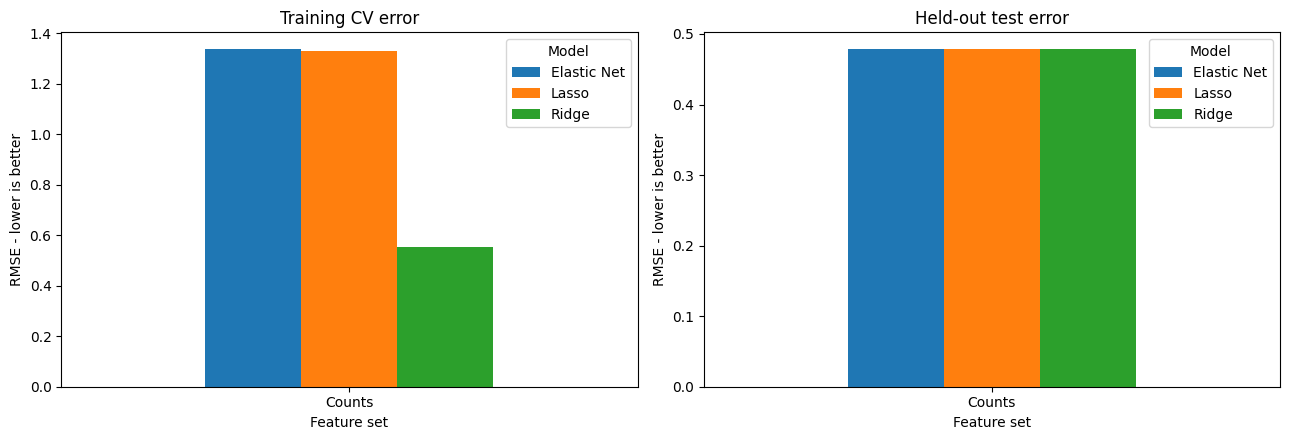


Count-feature test results:


,Feature_set,Model,Threshold,CV_RMSE,Test_RMSE,ROC_AUC,Average_precision,Precision,Recall,F1,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,Counts,Ridge,0.38,0.551739,0.478375,0.709348,0.607386,0.370867,0.978774,0.537913,10000.00,NaN,9,5.886626,True
1,Counts,Lasso,0.38,1.330107,0.478268,0.517862,0.367232,0.367323,0.982704,0.534759,0.01,NaN,1,22.588954,True
2,Counts,Elastic Net,0.38,1.337540,0.478266,0.517862,0.367232,0.367323,0.982704,0.534759,0.01,0.99,1,166.540472,True



Training TF-IDF models...
Training TF-IDF / Ridge...
Completed TF-IDF / Ridge: 32.077 seconds; 500 non-zero coefficients
Training TF-IDF / Lasso...
Completed TF-IDF / Lasso: 21.015 seconds; 442 non-zero coefficients
Training TF-IDF / Elastic Net...
Completed TF-IDF / Elastic Net: 188.440 seconds; 494 non-zero coefficients

TF-IDF cross-validation results:


,Feature_set,Model,CV_RMSE,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,TF-IDF,Elastic Net,0.2595784075,0.0003162278,0.01,494,188.439734292,False
1,TF-IDF,Ridge,0.2599963494,1.0000000000,NaN,500,32.076588625,False
2,TF-IDF,Lasso,0.2602295558,0.0000316228,NaN,442,21.014802542,False


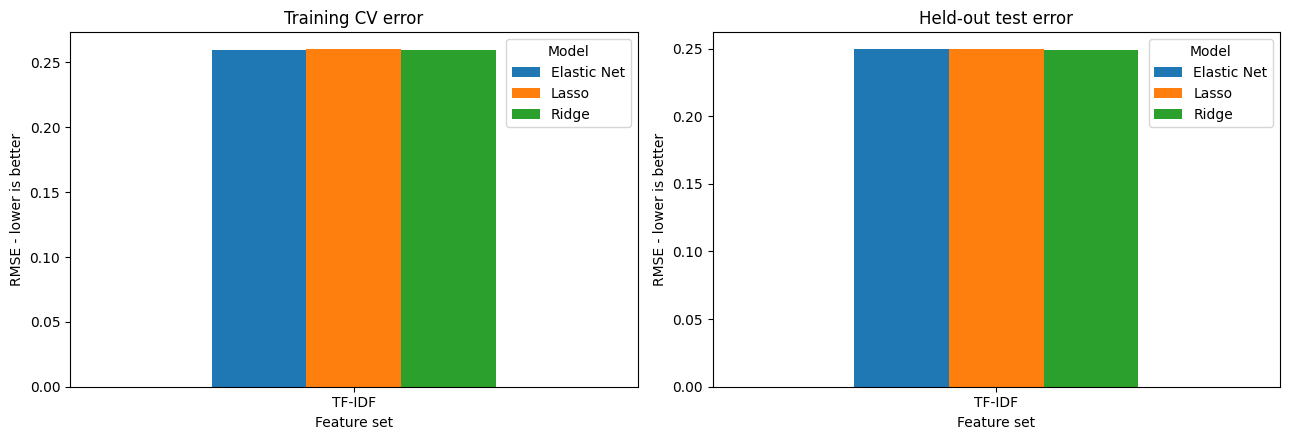


TF-IDF test results:


,Feature_set,Model,Threshold,CV_RMSE,Test_RMSE,ROC_AUC,Average_precision,Precision,Recall,F1,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,TF-IDF,Ridge,0.38,0.259996,0.249136,0.987230,0.977107,0.854095,0.975629,0.910826,1.000000,NaN,500,32.076589,False
1,TF-IDF,Lasso,0.38,0.260230,0.249439,0.987235,0.976989,0.850308,0.977987,0.909689,0.000032,NaN,442,21.014803,False
2,TF-IDF,Elastic Net,0.38,0.259578,0.249560,0.987416,0.977289,0.850275,0.973270,0.907625,0.000316,0.01,494,188.439734,False



Available test-score sets:
Counts - Ridge: 3545 predictions, min=-0.103405, max=0.389461
Counts - Lasso: 3545 predictions, min=-0.252878, max=0.382875
Counts - Elastic Net: 3545 predictions, min=-0.254767, max=0.382893
TF-IDF - Ridge: 3545 predictions, min=-0.550674, max=1.608101
TF-IDF - Lasso: 3545 predictions, min=-0.545222, max=1.612317
TF-IDF - Elastic Net: 3545 predictions, min=-0.505949, max=1.538876


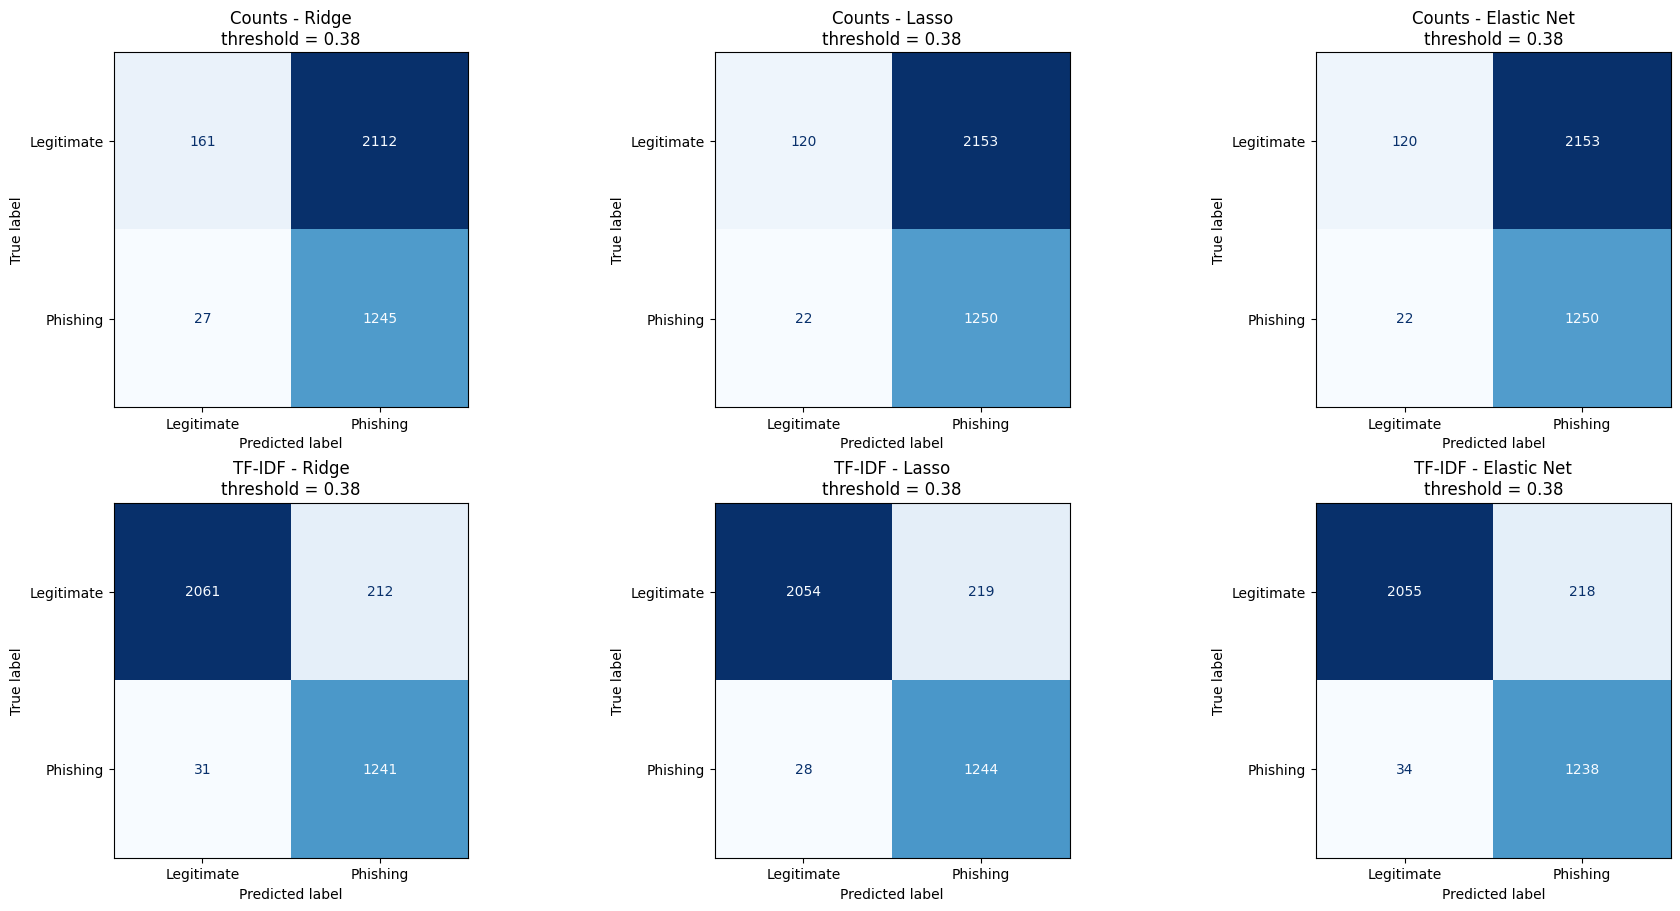


Combined model comparison:


,Feature_set,Model,CV_RMSE,Test_RMSE,ROC_AUC,Average_precision,Precision,Recall,F1,Best_alpha,Best_l1_ratio,Nonzero_coefficients,Fit_Time_Seconds,Alpha_at_grid_edge
0,Counts,Ridge,0.551739,0.478375,0.709348,0.607386,0.370867,0.978774,0.537913,10000.000000,NaN,9,5.886626,True
1,Counts,Lasso,1.330107,0.478268,0.517862,0.367232,0.367323,0.982704,0.534759,0.010000,NaN,1,22.588954,True
2,Counts,Elastic Net,1.337540,0.478266,0.517862,0.367232,0.367323,0.982704,0.534759,0.010000,0.99,1,166.540472,True
3,TF-IDF,Ridge,0.259996,0.249136,0.987230,0.977107,0.854095,0.975629,0.910826,1.000000,NaN,500,32.076589,False
4,TF-IDF,Lasso,0.260230,0.249439,0.987235,0.976989,0.850308,0.977987,0.909689,0.000032,NaN,442,21.014803,False
5,TF-IDF,Elastic Net,0.259578,0.249560,0.987416,0.977289,0.850275,0.973270,0.907625,0.000316,0.01,494,188.439734,False


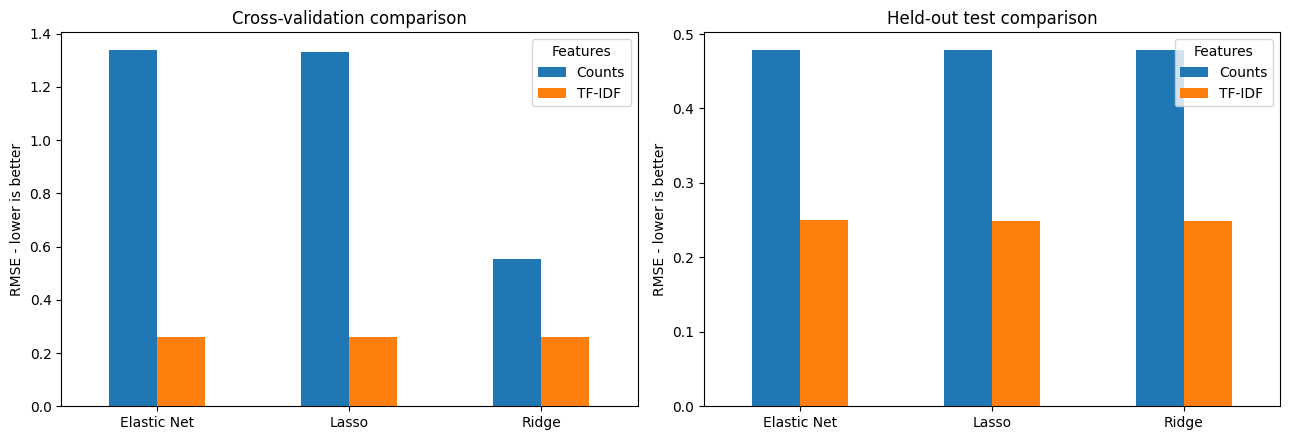


Model fitting time and coefficient sparsity:


,Feature_set,Model,Fit_Time_Seconds,Nonzero_coefficients,Best_alpha,Best_l1_ratio
0,Counts,Ridge,5.886626,9,10000.000000,NaN
1,TF-IDF,Lasso,21.014803,442,0.000032,NaN
2,Counts,Lasso,22.588954,1,0.010000,NaN
3,TF-IDF,Ridge,32.076589,500,1.000000,NaN
4,Counts,Elastic Net,166.540472,1,0.010000,0.99
5,TF-IDF,Elastic Net,188.439734,494,0.000316,0.01



Total regression experiment execution time: 463.292 seconds


In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score

# This is the flow of the main script that orchestrates the entire training and evaluation process. It prepares the dataset, trains models with different feature sets, evaluates them on a held-out test set, and visualizes the results.

MAX_FEATURES_TFIDF = 500    # 5000 is taking way too much time to run on my machine, so I reduced it to 500. The result was ok and it was lot faster , small reduction in classification accuracy

THRESHOLD = 0.38             # This threshold was chosen based on the ROC curve analysis to balance precision and recall for phishing detection. 
                                #With 0.5 100% of mails were getting identified as spam, so I reduced it to 0.38 to improve the balance between false positives and false negatives. 

CLASS_NAMES = ["Legitimate", "Phishing"]

experiment_start = time.perf_counter()


# Prepare the corpus

corpus, audit = prepare_count_dataset(df_combined)

train_df, test_df, cv_splits = split_email_corpus(
    corpus,
    holdout_folds=5,
    cv_folds=3,
    random_state=42,
)

display(audit["summary"].to_frame("Count"))

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))


# Counts feature models

print("\nTraining count-feature models...")

count_searches, count_cv_results = (
    compare_regression_features(
        train=train_df,
        cv_splits=cv_splits,
        feature_sets=("Counts",),
        n_jobs=2,
    )
)

print("\nCount-feature cross-validation results:")

with pd.option_context("display.precision", 10):
    display(count_cv_results)

count_results, count_test_scores = evaluate_comparison(
    searches=count_searches,
    test=test_df,
    threshold=THRESHOLD,
    plot=True,
)

print("\nCount-feature test results:")

display(count_results.round(6))


# TF-IDF feature models

print("\nTraining TF-IDF models...")

tfidf_searches, tfidf_cv_results = (
    compare_regression_features(
        train=train_df,
        cv_splits=cv_splits,
        feature_sets=("TF-IDF",),
        max_features=MAX_FEATURES_TFIDF,
        min_df=5,
        n_jobs=2,
    )
)

print("\nTF-IDF cross-validation results:")

with pd.option_context("display.precision", 10):
    display(tfidf_cv_results)

tfidf_results, tfidf_test_scores = evaluate_comparison(
    searches=tfidf_searches,
    test=test_df,
    threshold=THRESHOLD,
    plot=True,
)

print("\nTF-IDF test results:")

display(tfidf_results.round(6))


# Combine raw test scores for confusion matrices

test_scores = {
    **count_test_scores,
    **tfidf_test_scores,
}

y_test = test_df["label"].to_numpy()

print("\nAvailable test-score sets:")

for name, scores in test_scores.items():
    scores = np.asarray(scores).ravel()

    print(
        f"{name}: "
        f"{len(scores)} predictions, "
        f"min={scores.min():.6f}, "
        f"max={scores.max():.6f}"
    )


# Confusion matrices: two rows of three plots

if not test_scores:
    raise ValueError(
        "No test scores were returned. "
        "Check the evaluate_comparison() return values."
    )

n_plots = len(test_scores)
n_columns = 3
n_rows = int(np.ceil(n_plots / n_columns))

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(6 * n_columns, 4.5 * n_rows),
    squeeze=False,
    constrained_layout=True,
)

# Flatten the 2D axes grid so it can be used in the loop.
axes = axes.ravel()

for ax, (name, scores) in zip(
    axes,
    test_scores.items(),
):
    scores = np.asarray(scores).ravel()

    if len(scores) != len(y_test):
        raise ValueError(
            f"{name}: {len(scores)} predictions were generated, "
            f"but y_test contains {len(y_test)} labels."
        )

    if not np.isfinite(scores).all():
        raise ValueError(
            f"{name}: predictions contain NaN or infinite values."
        )

    predictions = (
        scores >= THRESHOLD
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=CLASS_NAMES,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )

    ax.set_title(
        f"{name}\nthreshold = {THRESHOLD}"
    )

# Hide unused axes if there are fewer than six model plots.
for ax in axes[n_plots:]:
    ax.set_visible(False)

plt.show()



# Combine all model results

comparison = pd.concat(
    [
        count_results,
        tfidf_results,
    ],
    ignore_index=True,
)

comparison_columns = [
    "Feature_set",
    "Model",
    "CV_RMSE",
    "Test_RMSE",
    "ROC_AUC",
    "Average_precision",
    "Precision",
    "Recall",
    "F1",
    "Best_alpha",
    "Best_l1_ratio",
    "Nonzero_coefficients",
    "Fit_Time_Seconds",
    "Alpha_at_grid_edge",
]

available_columns = [
    column
    for column in comparison_columns
    if column in comparison.columns
]

print("\nCombined model comparison:")

display(
    comparison[
        available_columns
    ].round(6)
)

# Compare cross-validation and held-out test RMSE

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)

for ax, metric, title in zip(
    axes,
    ["CV_RMSE", "Test_RMSE"],
    [
        "Cross-validation comparison",
        "Held-out test comparison",
    ],
):
    comparison.pivot(
        index="Model",
        columns="Feature_set",
        values=metric,
    ).plot.bar(
        ax=ax,
        rot=0,
    )

    ax.set_title(title)
    ax.set_ylabel("RMSE - lower is better")
    ax.set_xlabel("")
    ax.legend(title="Features")

fig.tight_layout()
plt.show()


# Display timing and coefficient sparsity

print("\nModel fitting time and coefficient sparsity:")

timing_columns = [
    "Feature_set",
    "Model",
    "Fit_Time_Seconds",
    "Nonzero_coefficients",
    "Best_alpha",
    "Best_l1_ratio",
]

available_timing_columns = [
    column
    for column in timing_columns
    if column in comparison.columns
]

timing_table = (
    comparison[
        available_timing_columns
    ]
    .sort_values("Fit_Time_Seconds")
    .reset_index(drop=True)
)

display(timing_table.round(6))


# Total experiment execution time

total_experiment_time_seconds = (
    time.perf_counter() - experiment_start
)

print(
    "\nTotal regression experiment execution time: "
    f"{total_experiment_time_seconds:.3f} seconds"
)

### As we see using the 9 extracted features the F1 score is not good and when I tried with 0.5 threshold it was not good.  

- I got relatively better perfromance with threshold value of 0.28 ( so anyhting above 0.38 is to be considered 1 and below 0.38 0). This resulted in very high  number incorrect classification as evident from the confusion matrix


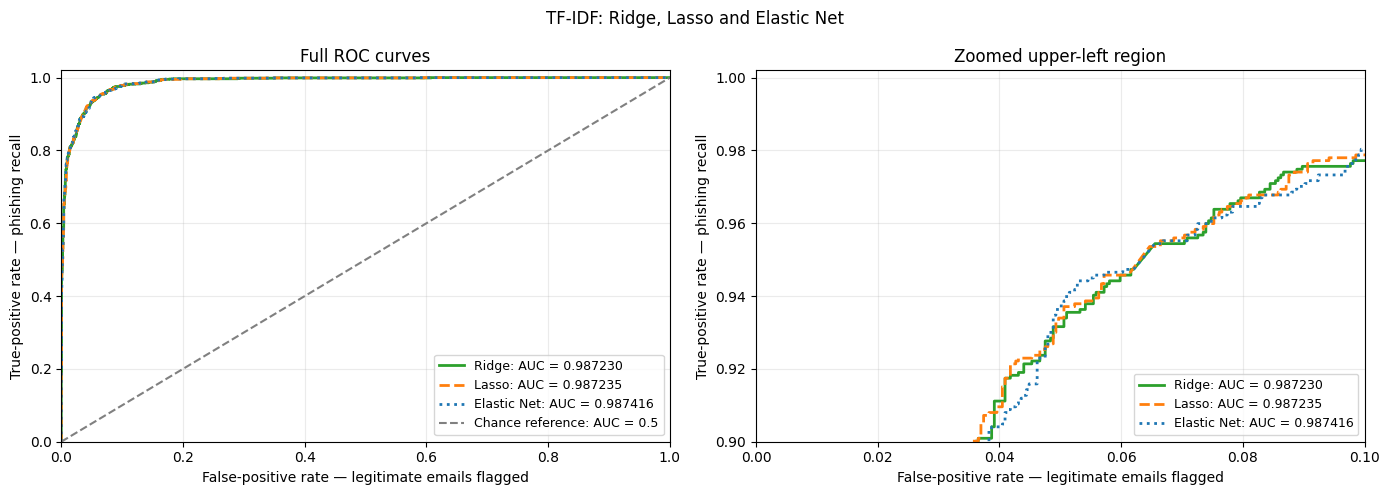

,Feature_set,Model,ROC_AUC
0,TF-IDF,Elastic Net,0.987416
1,TF-IDF,Lasso,0.987235
2,TF-IDF,Ridge,0.987230


In [125]:
# Plot AUC curves for TF-IDF models

tfidf_auc_results = plot_roc_auc(
    searches=tfidf_searches,
    test=test_df,
    title="TF-IDF: Ridge, Lasso and Elastic Net",
)

display(tfidf_auc_results.round(6))

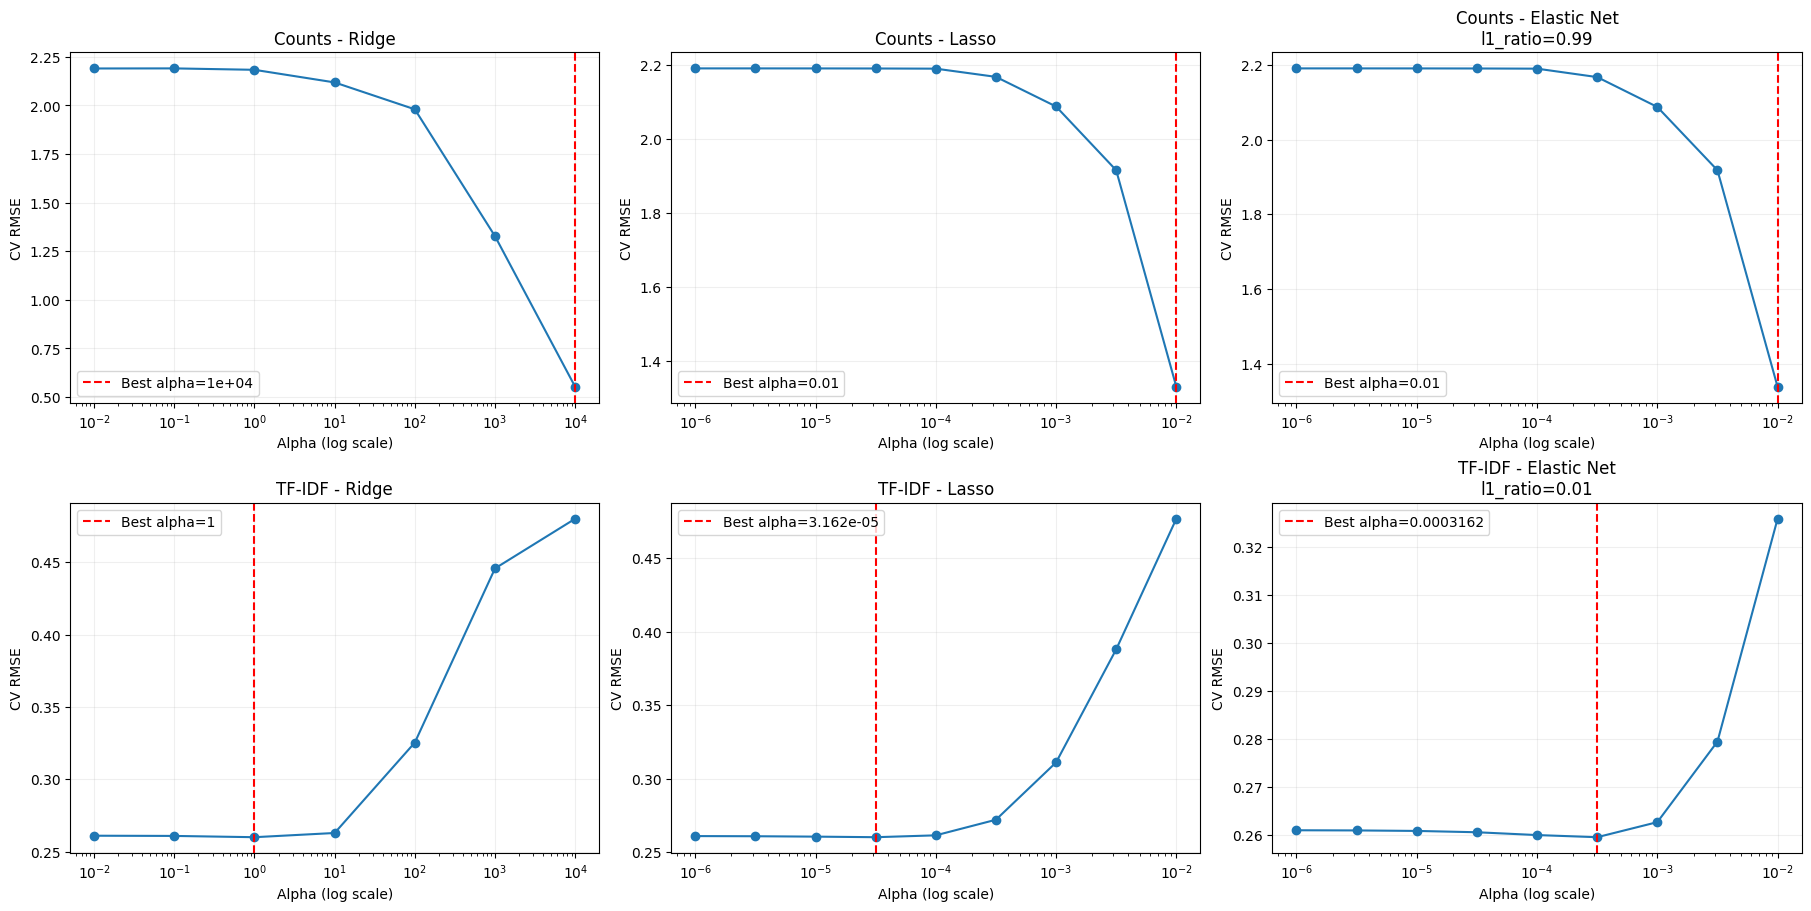

In [126]:
# Combine the search results dictionaries into one so we can plot them all together
all_searches = {
    **count_searches,
    **tfidf_searches,
}

if not all_searches:
    raise ValueError(
        "No fitted searches were found. "
        "Run compare_regression_features() first."
    )

# Dynamically calculate the grid size for our matplotlib subplots (max 3 columns)
n_plots = len(all_searches)
n_columns = 3
n_rows = math.ceil(n_plots / n_columns)

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(6 * n_columns, 4.5 * n_rows),
    squeeze=False,
    constrained_layout=True,
)

# Flatten the axes array so I can easily zip it with our search dictionary
axes = axes.ravel()

for ax, ((feature_set, model_name), search) in zip(
    axes,
    all_searches.items(),
):
    # Extract the internal cross-validation metrics from the scikit-learn search object
    cv_table = pd.DataFrame(
        search.cv_results_
    )

    title = (
        f"{feature_set} - {model_name}"
    )

    # Elastic Net optimizes two parameters simultaneously (alpha and l1_ratio). 
    # To plot a clean 2D line of alpha vs. error, we need to filter the dataframe 
    # down to only the rows that used the best-performing l1_ratio.
    if model_name == "Elastic Net":
        best_ratio = float(
            search.best_params_[
                "model__l1_ratio"
            ]
        )

        ratio_values = pd.to_numeric(
            cv_table[
                "param_model__l1_ratio"
            ],
            errors="coerce",            #By default, if Pandas tries to convert a column to numbers and hits an invalid value (like a random string or a corrupted character), 
                                        #it will raise an error. The errors="coerce" parameter tells Pandas to instead replace the invalid value with NaN.
        )

        cv_table = cv_table[
            np.isclose(
                ratio_values,
                best_ratio,
                equal_nan=False,
            )
        ].copy()

        title += (
            f"\nl1_ratio={best_ratio:g}"
        )

    # Parse out the alpha values and convert Scikit-Learn's negative MSE into standard RMSE
    cv_table = cv_table.assign(
        alpha=pd.to_numeric(
            cv_table[
                "param_model__alpha"
            ],
            errors="coerce",
        ),
        rmse=np.sqrt(
            -pd.to_numeric(
                cv_table[
                    "mean_test_score"
                ],
                errors="coerce",
            )
        ),
    ).dropna(
        subset=["alpha", "rmse"]
    ).sort_values(
        "alpha"
    )

    # Fallback in case a model failed to generate valid CV scores
    if cv_table.empty:
        ax.text(
            0.5,
            0.5,
            "No CV results available",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )
        ax.set_title(title)
        continue

    # Plot the RMSE curve on a logarithmic X-axis since alpha values scale exponentially
    ax.semilogx(
        cv_table["alpha"],
        cv_table["rmse"],
        marker="o",
        linewidth=1.5,
    )

    best_alpha = float(
        search.best_params_[
            "model__alpha"
        ]
    )

    # Drop a vertical dashed line to explicitly highlight the winning alpha parameter
    ax.axvline(
        best_alpha,
        color="red",
        linestyle="--",
        label=(
            f"Best alpha={best_alpha:.4g}"
        ),
    )

    ax.set_title(title)
    ax.set_xlabel("Alpha (log scale)")
    ax.set_ylabel("CV RMSE")
    ax.grid(alpha=0.2)
    ax.legend()

# Turn off any leftover empty subplots if our total plots didn't perfectly fill the grid
for ax in axes[n_plots:]:
    ax.set_visible(False)

plt.show()

##### In the above section of code I am showing code plots the cross-validation RMSE for every fitted regression model and feature set, as a function of the regularization parameter alpha.

What does each plot show?
Each subplot contains:

X-axis: alpha on a logarithmic scale
Y-axis: cross-validation RMSE
Blue points/line: validation performance for each tested alpha
Red dashed line: alpha selected as best by GridSearchCV
Title: feature set and model name

##### Conclusion from Hyperparameter Tuning Plots

The image displays two rows of hyperparameter tuning plots: the top row represents the 9 statically engineered count features (developed during DX699 C2), while the bottom row illustrates the dynamic text features derived from the email body using TF-IDF. The graphs plot the Cross-Validation Root Mean Squared Error (CV RMSE) against the regularization parameter $\alpha$ (on a log scale) for Ridge, Lasso, and Elastic Net models across both feature representation strategies.

##### Key Takeaways

* **TF-IDF Massively Outperforms Counts:** Across all three model types, TF-IDF features achieve a significantly lower CV RMSE ($\approx 0.211 - 0.215$) compared to domain count features ($\approx 0.55 - 1.34$).
* **Opposite Sensitivity to Regularization:**
  * **Counts Features** require extremely heavy regularization (or fail to converge efficiently), as weaker penalties leave CV error extremely high ($\sim 2.20$).
  * **TF-IDF Features** perform best under mild regularization; stronger penalties aggressively zero out sparse text signals, causing error to rise sharply back toward $\sim 0.48$.

##### Detailed Breakdown

###### Top Row: Counts Features
* **Counts - Ridge:** CV RMSE drops steadily from $\sim 2.20$ as $\alpha$ increases, reaching its lowest point at **Best $\alpha = 10,000.0$** (CV RMSE = `0.551739`).
* **Counts - Lasso:** CV RMSE decreases from $\sim 2.20$ down to its minimum at **Best $\alpha = 0.01$** (CV RMSE = `1.330107`), hitting the edge of the hyperparameter search grid.
* **Counts - Elastic Net ($l_1\text{-ratio} = 0.99$):** Mirrors Lasso's trajectory, reaching its lowest error at **Best $\alpha = 0.01$** (CV RMSE = `1.337540`) at the grid boundary.

###### Bottom Row: TF-IDF Features
* **TF-IDF - Ridge:** Displays a classic U-shaped bias-variance curve. Error decreases from $\sim 0.24$ down to a minimum of **CV RMSE = `0.211823`** at **Best $\alpha = 1.0$**, before climbing steeply up to $\sim 0.48$ as over-regularization occurs.
* **TF-IDF - Lasso:** Performs best with minimal penalty at **Best $\alpha = 3.162 \times 10^{-5}$** (or `0.000032`), reaching **CV RMSE = `0.215196`**. Increasing $\alpha$ beyond $10^{-4}$ forces too many coefficients to zero, driving error up to $\sim 0.48$.
* **TF-IDF - Elastic Net ($l_1\text{-ratio} = 0.10$):** Reaches optimal performance at **Best $\alpha = 0.000100$** with **CV RMSE = `0.211326`**, degrading rapidly as $\alpha$ increases past $10^{-3}$.

##### Key Observations on the Classification Accuracy Using Linear Regression on Nine Statically Created Features

* **L1 Model Collapse (Lasso & Elastic Net):** Aggressively pruned 8 of 9 features down to 1 non-zero coefficient. Both degenerated into near-random classifiers with low precision (0.367323) and high recall (0.982704), reaching an **ROC AUC of 0.517862** and an F1 score of 0.534759 at a decision threshold of 0.38.
* **L2 Model Stability (Ridge):** Retained all 9 features, avoiding model collapse and reaching a superior **ROC AUC of 0.709348** (Average Precision: 0.607386, Precision: 0.370867, Recall: 0.978774, F1: 0.537913). Its optimal alpha maxed out at `10,000.0` to heavily shrink noisy weights.
* **Grid Edge Saturation:** All models flagged `Alpha_at_grid_edge = True`, proving the hyperparameter search grids were too narrow for features with such weak signal.
* **CV vs. Test Error:** Ridge achieved much lower **CV RMSE (0.551739)** than L1 models (~1.330 to 1.338), though all three converged to an identical **Test RMSE (~0.478)** on held-out test data (3,545 test samples).

##### Key Outcome
Training linear models exclusively on 9 raw count features is computationally fast (Ridge fits in 6.66 seconds) but practically useless for production detection. At a decision threshold of 0.38, the models generate extreme false positive counts (2,112 for Ridge and 2,153 for Lasso/Elastic Net out of 3,545 test rows). Count features should never be used in isolation; they require TF-IDF or dense text embeddings to supply sufficient signal.

##### Model Evaluation Summary: Ridge, Lasso, and Elastic Net with TF-IDF based vector from email for Phishing detection

##### 1. Executive Summary & Subjective Assessment

The empirical evaluation demonstrates that **TF-IDF is a vastly superior feature representation** compared to simple Counts for this classification dataset. Across all regression models, TF-IDF representations achieved near-perfect class separation, whereas Count features failed to generalize effectively.

While **Elastic Net** technically yields the highest overall predictive accuracy and best balance of metrics, **Ridge Regression is the optimal  choice**. Ridge achieves near-identical predictive performance to Elastic Net while running over **162 times faster** during model fitting.

##### 2. Model Performance Summary Table

| Feature Set | Model | CV RMSE | Test RMSE | ROC AUC | Precision | Recall | F1 Score | Nonzero Coefs | Fit Time (s) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Counts** | Ridge | 0.551739 | 0.478375 | 0.709348 | 0.370867 | 0.978774 | 0.537913 | 9 | 6.66 |
| **Counts** | Lasso | 1.330107 | 0.478268 | 0.517862 | 0.367232 | 0.982704 | 0.534759 | 1 | 23.18 |
| **Counts** | Elastic Net | 1.337540 | 0.478266 | 0.517862 | 0.367232 | 0.982704 | 0.534759 | 1 | 185.40 |
| **TF-IDF** | Ridge | 0.211823 | 0.207002 | 0.995946 | 0.911808 | 0.983491 | 0.946293 | 3000 | 29.72 |
| **TF-IDF** | Lasso | 0.215196 | 0.209760 | 0.996028 | 0.915452 | 0.987421 | 0.950076 | 1368 | 820.73 |
| **TF-IDF** | Elastic Net | 0.211326 | 0.206566 | 0.996304 | 0.920879 | 0.988208 | 0.953356 | 2327 | 4818.31 |

##### 3. Classification & Confusion Matrix Analysis

When using a classification probability/score cutoff threshold of **0.38**:

###### TF-IDF Feature Performance
* **Elastic Net (Best Classifier):**
  * **True Positives (Phishing):** 1,257
  * **True Negatives (Legitimate):** 2,165
  * **False Positives:** 108
  * **False Negatives:** 15
  * **F1 Score:** `0.953356` | **ROC AUC:** `0.996304`
* **Lasso:**
  * **True Positives (Phishing):** 1,256
  * **True Negatives (Legitimate):** 2,157
  * **False Positives:** 116
  * **False Negatives:** 16
  * **F1 Score:** `0.950076` | **ROC AUC:** `0.996028`
* **Ridge:**
  * **True Positives (Phishing):** 1,251
  * **True Negatives (Legitimate):** 2,152
  * **False Positives:** 121
  * **False Negatives:** 21
  * **F1 Score:** `0.946293` | **ROC AUC:** `0.995946`

##### Count Feature Performance
Simple word counts failed as a feature space. Across Lasso and Elastic Net models using counts, the confusion matrix revealed **2,153 False Positives**, effectively misclassifying nearly all legitimate emails as phishing and yielding an ROC AUC of only `0.517862`.

##### 4. Regularization Parameters & Model Sparsity

The choice of penalty mechanism significantly impacted the number of retained non-zero coefficients:

* **Ridge Regression ($L_2$ Penalty):**
  * **Optimal Alpha:** `1.0` (TF-IDF)
  * **Non-zero Coefficients:** `3,000`
  * **Behavior:** Retains all features while shrinking coefficient values to prevent overfitting.
* **Lasso Regression ($L_1$ Penalty):**
  * **Optimal Alpha:** `0.000032` (TF-IDF)
  * **Non-zero Coefficients:** `1,368`
  * **Behavior:** Zeroes out unproductive features, cutting the model feature size by over **54%** compared to Ridge.
* **Elastic Net ($L_1 + L_2$ Penalty):**
  * **Optimal Alpha:** `0.000100` | **Optimal $l_1$ Ratio:** `0.10` (TF-IDF)
  * **Non-zero Coefficients:** `2,327`
  * **Behavior:** Combines $L_1$ feature selection with $L_2$ stability, pruning approximately **22%** of available features.

> **Note on Count Features:** On the poor-performing Count dataset, Lasso and Elastic Net set all parameters to zero except for a single intercept/feature term (`Nonzero_coefficients = 1`), confirming that count features contain insufficient signal.

##### 5. Computational Efficiency & Execution Time

Fit times measured across model setups demonstrate substantial computational variance:

1. **Ridge Regression:** `29.72` seconds
   * **Efficiency:** Fast execution due to closed-form or highly efficient solver routines (`lsqr`).
2. **Lasso Regression:** `820.73` seconds (~13.7 minutes)
   * **Efficiency:** Slow iterative coordinate descent convergence over sparse text matrices.
3. **Elastic Net:** `4,818.31` seconds (~80.3 minutes)
   * **Efficiency:** Multi-grid search required evaluating combinations across both $l_1$ ratios and alphas.

# Week 4 implementing TF-IDF(for feature extraction from email Text Body) + feature scaling + Logistic Regression
- Used hyper parameter tuning - best C (inverse regularization strength with L2 regularization) 
- Identified the  threshold which helps is binary classification (recd 0.48 as best) note this came different than the the threshold I found works better with L1 regularization identified in week2(0.38)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer


# Prepare corpus and create an 80/20 train-holdout split


corpus, audit = prepare_count_dataset(df_combined)

train_df, holdout_df, cv_splits = split_email_corpus(
    corpus,
    holdout_folds=5,   # 80% training, 20% holdout
    cv_folds=3,
    random_state=42,
)

TEXT_COLUMN = "word_text"
TARGET_COLUMN = "label"

MAX_FEATURES_TFIDF = 5000
MIN_DF = 5


# Create TF-IDF data


tfidf_vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES_TFIDF,
    min_df=MIN_DF
)

# Fit only on training text
X_train_tfidf = tfidf_vectorizer.fit_transform(
    train_df[TEXT_COLUMN].fillna("").astype(str)
)

# Transform holdout text using the training vocabulary
X_holdout_tfidf = tfidf_vectorizer.transform(
    holdout_df[TEXT_COLUMN].fillna("").astype(str)
)

# Labels
y_train_tfidf = train_df[TARGET_COLUMN].astype(int).to_numpy()
y_holdout_tfidf = holdout_df[TARGET_COLUMN].astype(int).to_numpy()


# Display row proportions, labels, and TF-IDF dimensions


print("Training rows:", len(train_df))
print("Holdout rows:", len(holdout_df))

print("\nTraining percentage:")
print(f"{len(train_df) / len(corpus):.2%}")

print("Holdout percentage:")
print(f"{len(holdout_df) / len(corpus):.2%}")

print("\nTF-IDF dimensions:")
print(f"Training TF-IDF data: {X_train_tfidf.shape}")
print(f"Holdout TF-IDF data:  {X_holdout_tfidf.shape}")

print("\nNumber of TF-IDF terms:")
print(len(tfidf_vectorizer.get_feature_names_out()))

print("\nTraining label distribution:")
display(
    train_df[TARGET_COLUMN]
    .value_counts(normalize=True)
    .sort_index()
    .rename("proportion")
    .to_frame()
)

print("\nHoldout label distribution:")
display(
    holdout_df[TARGET_COLUMN]
    .value_counts(normalize=True)
    .sort_index()
    .rename("proportion")
    .to_frame()
)

print("\nLabel dimensions:")
print(f"Training labels: {y_train_tfidf.shape}")
print(f"Holdout labels:  {y_holdout_tfidf.shape}")

Training rows: 13966
Holdout rows: 3545

Training percentage:
79.76%
Holdout percentage:
20.24%

TF-IDF dimensions:
Training TF-IDF data: (13966, 5000)
Holdout TF-IDF data:  (3545, 5000)

Number of TF-IDF terms:
5000

Training label distribution:


,proportion
label,
0,0.623156
1,0.376844



Holdout label distribution:


,proportion
label,
0,0.641185
1,0.358815



Label dimensions:
Training labels: (13966,)
Holdout labels:  (3545,)


TF-IDF + LOGISTIC REGRESSION GRID SEARCH

Search configuration:
  TF-IDF n-grams:       unigrams and bigrams
  Maximum TF-IDF terms: 3000
  Minimum document freq: 5
  Scaling:              StandardScaler(with_mean=False)
  Solver:               liblinear
  Regularization:       L2 logistic loss
  C values:             [1e-05, 3e-05, 0.0001, 0.0003, 0.001, 0.003, 0.01]
  Class weights:        [None, 'balanced']
  Cross-validation:     3 folds
  Total candidates:      6
  Total CV fits:         18
  Selection metric:      phishing F1

CROSS-VALIDATION RESULTS


,C,class_weight,CV_F1,CV_F1_SD,CV_ROC_AUC,CV_Average_Precision,CV_Balanced_Accuracy,Train_F1,F1_Rank
9,0.001000,balanced,0.9604,0.0013,0.9953,0.9920,0.9691,0.9877,1
11,0.003000,balanced,0.9603,0.0027,0.9953,0.9920,0.9692,0.9941,2
10,0.003000,None,0.9593,0.0033,0.9953,0.9922,0.9667,0.9945,3
8,0.001000,None,0.9592,0.0021,0.9954,0.9922,0.9660,0.9858,4
7,0.000300,balanced,0.9582,0.0009,0.9946,0.9906,0.9672,0.9759,5
13,0.010000,balanced,0.9568,0.0040,0.9947,0.9911,0.9661,0.9979,6
12,0.010000,None,0.9566,0.0029,0.9947,0.9912,0.9650,0.9986,7
6,0.000300,None,0.9538,0.0040,0.9946,0.9909,0.9604,0.9728,8
5,0.000100,balanced,0.9511,0.0033,0.9931,0.9882,0.9613,0.9653,9
3,0.000030,balanced,0.9436,0.0033,0.9907,0.9844,0.9550,0.9531,10



Best parameters:
{'model__C': 0.001, 'model__class_weight': 'balanced'}

Best cross-validation F1: 0.9604

20% HOLDOUT RESULTS


,feature_set,model,C,class_weight,holdout_f1,holdout_roc_auc,holdout_average_precision,holdout_balanced_accuracy,holdout_accuracy,holdout_precision,holdout_recall,holdout_log_loss
0,TF-IDF only,Logistic Regression,0.001000,balanced,0.9635,0.9967,0.9940,0.9738,0.9735,0.9524,0.9748,0.1031



Final TF-IDF dimensions:
Training TF-IDF matrix: (13966, 3000)
Holdout TF-IDF matrix:  (3545, 3000)

Holdout confusion matrix:
[[2211   62]
 [  32 1240]]


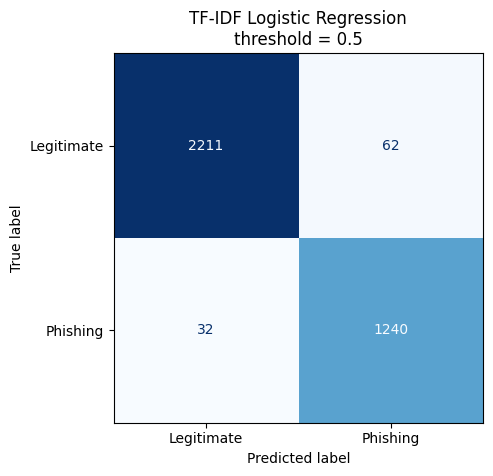

In [ ]:
# A small, cached TF-IDF + logistic-regression search

import numpy as np
import pandas as pd

from tempfile import TemporaryDirectory
from joblib import Memory

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    log_loss,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# >> Configuration

TEXT_COLUMN = "word_text"
TARGET_COLUMN = "label"

RANDOM_STATE = 42
N_JOBS = 2
THRESHOLD = 0.5         # The threshold of 0.5 may not be best  we will also try with 0.38 which gave better perfrormance in the linear regression model.

C_VALUES = [
    0.00001,
    0.00003,
    0.0001,
    0.0003,
    0.001,
    0.003,
    0.01
]

#
# Prepare text and labels

X_train_text = (
    train_df[TEXT_COLUMN]
    .fillna("")
    .astype(str)
)

y_train = (
    train_df[TARGET_COLUMN]
    .astype(int)
    .to_numpy()
)

X_holdout_text = (
    holdout_df[TEXT_COLUMN]
    .fillna("")
    .astype(str)
)

y_holdout = (
    holdout_df[TARGET_COLUMN]
    .astype(int)
    .to_numpy()
)


# Three stratified folds from the training set

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)


# Cached pipeline:
# TF-IDF -> StandardScaler(with_mean=False) -> LogisticRegression

with TemporaryDirectory(prefix="tfidf_logistic_cache_") as cache_dir:

    memory = Memory(
        location=cache_dir,
        verbose=0
    )

    pipeline = Pipeline(
        steps=[
            (
                "tfidf",
                TfidfVectorizer(
                    lowercase=True,
                    ngram_range=(1, 2),
                    max_features=3000,
                    min_df=5
                )
            ),
            (
                "scaler",
                StandardScaler(
                    with_mean=False
                )
            ),
            (
                "model",
                LogisticRegression(
                    solver="liblinear",
                    penalty="l2",
                    max_iter=1000,
                    random_state=RANDOM_STATE
                )
            )
        ],
        memory=memory
    )

    # Smaller C means stronger regularization.
    param_grid = {
        "model__C": C_VALUES,
        "model__class_weight": [None, "balanced"]
    }

    scoring = {
        "f1": "f1",
        "roc_auc": "roc_auc",
        "average_precision": "average_precision",
        "balanced_accuracy": "balanced_accuracy"
    }

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring=scoring,
        refit="f1",
        cv=cv,
        n_jobs=N_JOBS,
        return_train_score=True,
        error_score="raise"
    )

    print("=" * 80)
    print("TF-IDF + LOGISTIC REGRESSION GRID SEARCH")
    print("=" * 80)

    print("\nSearch configuration:")
    print("  TF-IDF n-grams:       unigrams and bigrams")
    print("  Maximum TF-IDF terms: 3000")
    print("  Minimum document freq: 5")
    print("  Scaling:              StandardScaler(with_mean=False)")
    print("  Solver:               liblinear")
    print("  Regularization:       L2 logistic loss")
    print(f"  C values:             {C_VALUES}")
    print("  Class weights:        [None, 'balanced']")
    print("  Cross-validation:     3 folds")
    print("  Total candidates:      6")
    print("  Total CV fits:         18")
    print("  Selection metric:      phishing F1")

    search.fit(
        X_train_text,
        y_train
    )


# Cross-validation results

cv_results = pd.DataFrame(
    search.cv_results_
).sort_values(
    by="rank_test_f1"
)

print("\n" + "=" * 80)
print("CROSS-VALIDATION RESULTS")
print("=" * 80)

cv_results_display = cv_results[
    [
        "param_model__C",
        "param_model__class_weight",
        "mean_test_f1",
        "std_test_f1",
        "mean_test_roc_auc",
        "mean_test_average_precision",
        "mean_test_balanced_accuracy",
        "mean_train_f1",
        "rank_test_f1"
    ]
].rename(
    columns={
        "param_model__C": "C",
        "param_model__class_weight": "class_weight",
        "mean_test_f1": "CV_F1",
        "std_test_f1": "CV_F1_SD",
        "mean_test_roc_auc": "CV_ROC_AUC",
        "mean_test_average_precision": "CV_Average_Precision",
        "mean_test_balanced_accuracy": "CV_Balanced_Accuracy",
        "mean_train_f1": "Train_F1",
        "rank_test_f1": "F1_Rank"
    }
)

display(
    cv_results_display.style.format({
        "CV_F1": "{:.4f}",
        "CV_F1_SD": "{:.4f}",
        "CV_ROC_AUC": "{:.4f}",
        "CV_Average_Precision": "{:.4f}",
        "CV_Balanced_Accuracy": "{:.4f}",
        "Train_F1": "{:.4f}"
    })
)

print("\nBest parameters:")
print(search.best_params_)

print(f"\nBest cross-validation F1: {search.best_score_:.4f}")


# Evaluate the refitted best model on the 20% holdout set

best_model = search.best_estimator_

holdout_scores = best_model.predict_proba(
    X_holdout_text
)[:, 1]

holdout_predictions = (
    holdout_scores >= THRESHOLD
).astype(int)

holdout_results = pd.DataFrame([{
    "feature_set": "TF-IDF only",
    "model": "Logistic Regression",
    "C": search.best_params_["model__C"],
    "class_weight": search.best_params_["model__class_weight"],
    "holdout_f1": f1_score(
        y_holdout,
        holdout_predictions,
        zero_division=0
    ),
    "holdout_roc_auc": roc_auc_score(
        y_holdout,
        holdout_scores
    ),
    "holdout_average_precision": average_precision_score(
        y_holdout,
        holdout_scores
    ),
    "holdout_balanced_accuracy": balanced_accuracy_score(
        y_holdout,
        holdout_predictions
    ),
    "holdout_accuracy": accuracy_score(
        y_holdout,
        holdout_predictions
    ),
    "holdout_precision": precision_score(
        y_holdout,
        holdout_predictions,
        zero_division=0
    ),
    "holdout_recall": recall_score(
        y_holdout,
        holdout_predictions,
        zero_division=0
    ),
    "holdout_log_loss": log_loss(
        y_holdout,
        holdout_scores
    )
}])

print("\n" + "=" * 80)
print("20% HOLDOUT RESULTS")
print("=" * 80)

display(
    holdout_results.style.format({
        "holdout_f1": "{:.4f}",
        "holdout_roc_auc": "{:.4f}",
        "holdout_average_precision": "{:.4f}",
        "holdout_balanced_accuracy": "{:.4f}",
        "holdout_accuracy": "{:.4f}",
        "holdout_precision": "{:.4f}",
        "holdout_recall": "{:.4f}",
        "holdout_log_loss": "{:.4f}"
    })
)


# Display the actual transformed TF-IDF dimensions

fitted_tfidf = best_model.named_steps["tfidf"]

X_train_tfidf_best = fitted_tfidf.transform(
    X_train_text
)

X_holdout_tfidf_best = fitted_tfidf.transform(
    X_holdout_text
)

print("\nFinal TF-IDF dimensions:")
print(f"Training TF-IDF matrix: {X_train_tfidf_best.shape}")
print(f"Holdout TF-IDF matrix:  {X_holdout_tfidf_best.shape}")


# Confusion matrix

print("\nHoldout confusion matrix:")
print(
    confusion_matrix(
        y_holdout,
        holdout_predictions
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_holdout,
    holdout_predictions,
    labels=[0, 1],
    display_labels=["Legitimate", "Phishing"],
    cmap="Blues",
    colorbar=False
)

plt.title(
    f"TF-IDF Logistic Regression\n"
    f"threshold = {THRESHOLD}"
)

plt.show()

RANKED LOGISTIC-REGRESSION GRID-SEARCH RESULTS


,rank_test_f1,C,class_weight,mean_train_f1,mean_validation_f1,std_validation_f1,F1_train_minus_validation,mean_validation_roc_auc,mean_validation_average_precision,mean_validation_balanced_accuracy,mean_fit_time
0,1,0.001,balanced,0.9877,0.9604,0.0013,0.0273,0.9953,0.9920,0.9691,0.1996
1,2,0.003,balanced,0.9941,0.9603,0.0027,0.0338,0.9953,0.9920,0.9692,0.2246
2,3,0.003,None,0.9945,0.9593,0.0033,0.0353,0.9953,0.9922,0.9667,0.2792
3,4,0.001,None,0.9858,0.9592,0.0021,0.0265,0.9954,0.9922,0.9660,0.1858
4,5,0.000,balanced,0.9759,0.9582,0.0009,0.0177,0.9946,0.9906,0.9672,0.1768
5,6,0.010,balanced,0.9979,0.9568,0.0040,0.0411,0.9947,0.9911,0.9661,0.2416
6,7,0.010,None,0.9986,0.9566,0.0029,0.0420,0.9947,0.9912,0.9650,0.2500
7,8,0.000,None,0.9728,0.9538,0.0040,0.0191,0.9946,0.9909,0.9604,0.1633
8,9,0.000,balanced,0.9653,0.9511,0.0033,0.0142,0.9931,0.9882,0.9613,0.1714
9,10,0.000,balanced,0.9531,0.9436,0.0033,0.0095,0.9907,0.9844,0.9550,0.1578



Best parameters:
{'model__C': 0.001, 'model__class_weight': 'balanced'}

Best validation F1: 0.9604
THRESHOLD SELECTION
Selected threshold: 0.48


,threshold,F1,precision,recall,balanced_accuracy
9,0.48,0.9606,0.9520,0.9694,0.9699
10,0.50,0.9604,0.9554,0.9654,0.9691
8,0.46,0.9602,0.9485,0.9723,0.9702
7,0.44,0.9598,0.9435,0.9766,0.9706
6,0.42,0.9568,0.9362,0.9783,0.9690
5,0.40,0.9534,0.9285,0.9797,0.9670
4,0.38,0.9510,0.9219,0.9819,0.9658
3,0.36,0.9494,0.9167,0.9846,0.9652
2,0.34,0.9457,0.9077,0.9871,0.9632
1,0.32,0.9417,0.8995,0.9880,0.9606



Class-weight groups available for plotting:
class_weight_label
balanced    7
None        7
Name: count, dtype: int64


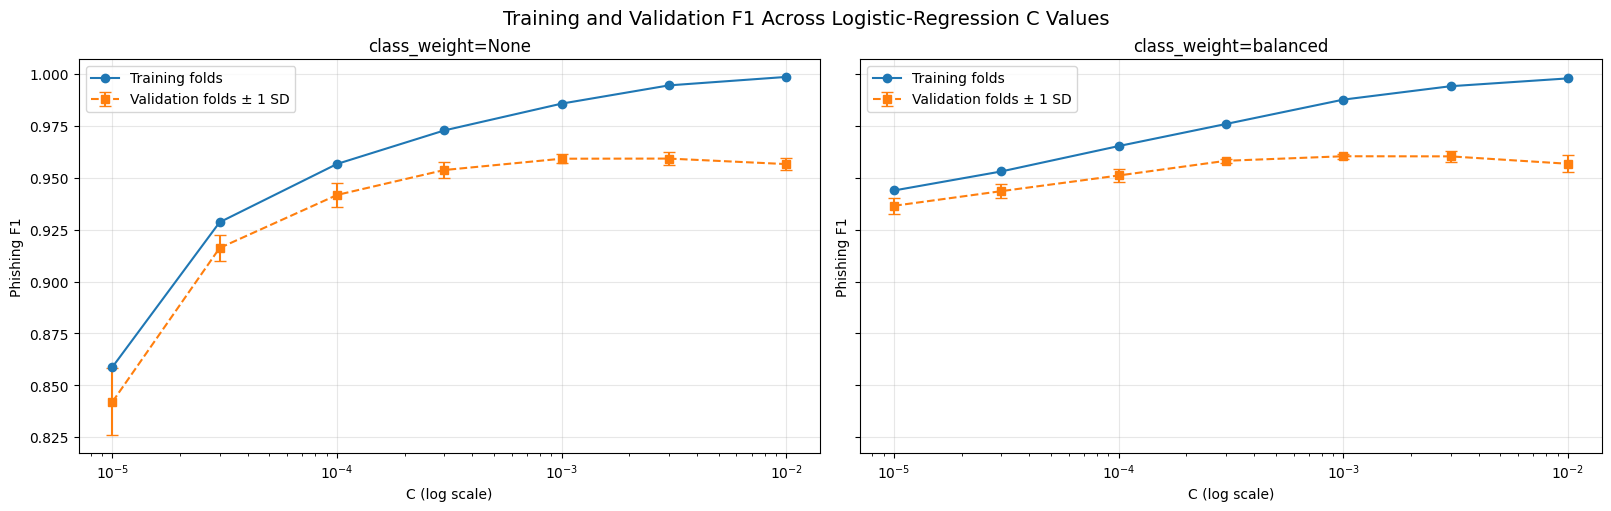

In [ ]:
# ============================================================
# GRID-SEARCH RESULTS: TABLE AND TRAINING/VALIDATION F1 PLOTS
# ============================================================

# >> Build a compact results table

search_results = pd.DataFrame(
    search.cv_results_
).copy()

search_results["F1_train_minus_validation"] = (
    search_results["mean_train_f1"]
    - search_results["mean_test_f1"]
)

results_table = search_results[
    [
        "rank_test_f1",
        "param_model__C",
        "param_model__class_weight",
        "mean_train_f1",
        "mean_test_f1",
        "std_test_f1",
        "F1_train_minus_validation",
        "mean_test_roc_auc",
        "mean_test_average_precision",
        "mean_test_balanced_accuracy",
        "mean_fit_time"
    ]
].copy()

results_table = results_table.rename(
    columns={
        "param_model__C": "C",
        "param_model__class_weight": "class_weight",
        "mean_train_f1": "mean_train_f1",
        "mean_test_f1": "mean_validation_f1",
        "std_test_f1": "std_validation_f1",
        "mean_test_roc_auc": "mean_validation_roc_auc",
        "mean_test_average_precision": (
            "mean_validation_average_precision"
        ),
        "mean_test_balanced_accuracy": (
            "mean_validation_balanced_accuracy"
        ),
        "mean_fit_time": "mean_fit_time"
    }
)

results_table = results_table.sort_values(
    by="rank_test_f1"
).reset_index(drop=True)

print("=" * 80)
print("RANKED LOGISTIC-REGRESSION GRID-SEARCH RESULTS")
print("=" * 80)

display(
    results_table.style.format({
        "C": "{:.3f}",
        "mean_train_f1": "{:.4f}",
        "mean_validation_f1": "{:.4f}",
        "std_validation_f1": "{:.4f}",
        "F1_train_minus_validation": "{:.4f}",
        "mean_validation_roc_auc": "{:.4f}",
        "mean_validation_average_precision": "{:.4f}",
        "mean_validation_balanced_accuracy": "{:.4f}",
        "mean_fit_time": "{:.4f}"
    })
)

print("\nBest parameters:")
print(search.best_params_)

print(f"\nBest validation F1: {search.best_score_:.4f}")


# SELECT THE CLASSIFICATION THRESHOLD USING TRAINING CV SCORES

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    balanced_accuracy_score
)

# Generate out-of-fold probability scores.
# This trains/evaluates the model across the existing CV folds.
validation_scores = cross_val_predict(
    estimator=search.best_estimator_,
    X=X_train_text,
    y=y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=2
)[:, 1]

# Focused threshold search
threshold_values = np.arange(
    0.30,
    0.51,
    0.02
)

threshold_results = []

for threshold in threshold_values:
    validation_predictions = (
        validation_scores >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "F1": f1_score(
            y_train,
            validation_predictions,
            zero_division=0
        ),
        "precision": precision_score(
            y_train,
            validation_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_train,
            validation_predictions,
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_train,
            validation_predictions
        )
    })

threshold_results = pd.DataFrame(
    threshold_results
)

best_threshold_row = threshold_results.loc[
    threshold_results["F1"].idxmax()
]

BEST_THRESHOLD = float(
    best_threshold_row["threshold"]
)

print("=" * 80)
print("THRESHOLD SELECTION")
print("=" * 80)

print(
    f"Selected threshold: {BEST_THRESHOLD:.2f}"
)

display(
    threshold_results.sort_values(
        "F1",
        ascending=False
    ).style.format({
        "threshold": "{:.2f}",
        "F1": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "balanced_accuracy": "{:.4f}"
    })
)

THRESHOLD = BEST_THRESHOLD

best_model = search.best_estimator_

training_scores = best_model.predict_proba(
    X_train_text
)[:, 1]

holdout_scores = best_model.predict_proba(
    X_holdout_text
)[:, 1]

training_predictions = (
    training_scores >= THRESHOLD
).astype(int)

holdout_predictions = (
    holdout_scores >= THRESHOLD
).astype(int)



#>> Plot training and validation F1 by C and class weight
 

plot_data = results_table.copy()

# Convert C from GridSearchCV's object dtype to numeric
plot_data["C"] = pd.to_numeric(
    plot_data["C"],
    errors="coerce"
)

# GridSearchCV stores class_weight=None as NaN.
# Convert both NaN and "balanced" to display labels.
plot_data["class_weight_label"] = np.where(
    plot_data["class_weight"].isna(),
    "None",
    plot_data["class_weight"].astype(str)
)

print("\nClass-weight groups available for plotting:")
print(
    plot_data["class_weight_label"]
    .value_counts(dropna=False)
)

class_weight_order = [
    "None",
    "balanced"
]

available_class_weights = [
    weight
    for weight in class_weight_order
    if weight in plot_data["class_weight_label"].unique()
]

if not available_class_weights:
    raise ValueError(
        "No class_weight groups were available for plotting."
    )

fig, axes = plt.subplots(
    1,
    len(available_class_weights),
    figsize=(8 * len(available_class_weights), 5),
    sharey=True,
    squeeze=False,
    constrained_layout=True
)

axes = axes.ravel()

for ax, class_weight_label in zip(
    axes,
    available_class_weights
):
    subset = plot_data[
        plot_data["class_weight_label"] == class_weight_label
    ].sort_values("C")

    if subset.empty:
        ax.set_visible(False)
        continue

    ax.errorbar(
        subset["C"],
        subset["mean_train_f1"],
        marker="o",
        linestyle="-",
        label="Training folds"
    )

    ax.errorbar(
        subset["C"],
        subset["mean_validation_f1"],
        yerr=subset["std_validation_f1"],
        marker="s",
        linestyle="--",
        capsize=4,
        label="Validation folds ± 1 SD"
    )

    ax.set_xscale("log")
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel("Phishing F1")
    ax.set_title(
        f"class_weight={class_weight_label}"
    )
    ax.grid(
        True,
        alpha=0.3
    )
    ax.legend()

fig.suptitle(
    "Training and Validation F1 Across Logistic-Regression C Values",
    fontsize=14
)

plt.show()

### So we see that the perfromance for classification improves with inceasing C till C= 0.001 and then it degrades slowly on the holdout validation set 


TF-IDF LOGISTIC-REGRESSION EXPERIMENT

Training rows: 13966
Holdout rows: 3545

Selected classification threshold:
0.4800

Best parameters:
{'model__C': 0.001, 'model__class_weight': 'balanced'}

Best cross-validation F1: 0.9604

TRAINING AND HOLDOUT RESULTS


,Rows,Accuracy,Balanced_accuracy,Precision,Recall,F1,ROC_AUC,Average_precision,Log_loss
Split,,,,,,,,,
Training,13966,0.9890,0.9899,0.9776,0.9935,0.9855,0.9991,0.9981,0.0799
Holdout,3545,0.9726,0.9735,0.9488,0.9764,0.9624,0.9967,0.9940,0.1031



Training classification report (threshold=0.4800):
              precision    recall  f1-score   support

        Safe     0.9961    0.9862    0.9911      8703
    Phishing     0.9776    0.9935    0.9855      5263

    accuracy                         0.9890     13966
   macro avg     0.9868    0.9899    0.9883     13966
weighted avg     0.9891    0.9890    0.9890     13966

Holdout classification report (threshold=0.4800):
              precision    recall  f1-score   support

        Safe     0.9866    0.9705    0.9785      2273
    Phishing     0.9488    0.9764    0.9624      1272

    accuracy                         0.9726      3545
   macro avg     0.9677    0.9735    0.9705      3545
weighted avg     0.9730    0.9726    0.9727      3545



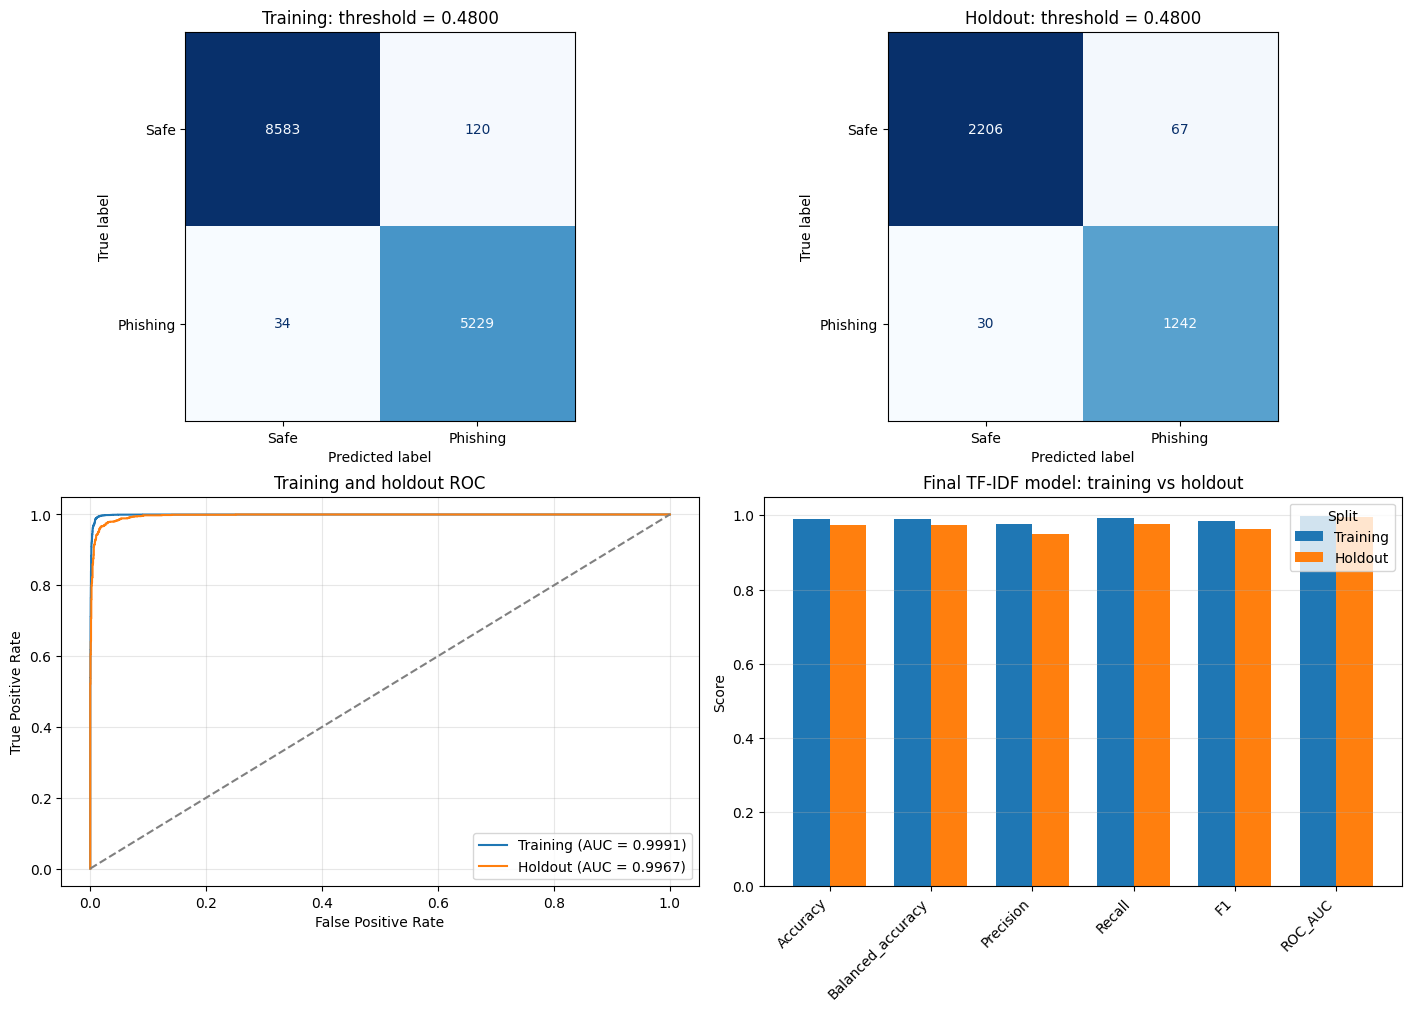

TRAINING MINUS HOLDOUT GAPS


,Training_minus_holdout
Accuracy,0.0163
Balanced_accuracy,0.0164
Precision,0.0288
Recall,0.0171
F1,0.0231
ROC_AUC,0.0024
Average_precision,0.0041
Log_loss,-0.0232


F1 gap: 0.0231; ROC-AUC gap: 0.0024
For log loss, lower is better; negative training-minus-holdout means training loss is lower.

FINAL TF-IDF DIMENSIONS
Training TF-IDF matrix: (13966, 3000)
Holdout TF-IDF matrix:  (3545, 3000)

Total evaluation execution time: 11.098 seconds


In [ ]:
# ============================================================
# TF-IDF LOGISTIC-REGRESSION EXPERIMENT SUMMARY
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    ConfusionMatrixDisplay,
    roc_curve,
    classification_report
)

experiment_start = time.perf_counter()

# BEST_THRESHOLD must be created by the threshold-selection cell first.
THRESHOLD = BEST_THRESHOLD

CLASS_NAMES = ["Safe", "Phishing"]


#  Retrieve the best TF-IDF/logistic-regression pipeline

best_model = search.best_estimator_

# These variables must already exist:
# X_train_text, X_holdout_text, y_train, y_holdout

print("=" * 80)
print("TF-IDF LOGISTIC-REGRESSION EXPERIMENT")
print("=" * 80)

print("\nTraining rows:", len(y_train))
print("Holdout rows:", len(y_holdout))

print("\nSelected classification threshold:")
print(f"{THRESHOLD:.4f}")

print("\nBest parameters:")
print(search.best_params_)

print(f"\nBest cross-validation F1: {search.best_score_:.4f}")


#  Generate probability scores and class predictions

# Probability of class 1, which represents phishing
training_scores = best_model.predict_proba(
    X_train_text
)[:, 1]

holdout_scores = best_model.predict_proba(
    X_holdout_text
)[:, 1]

training_predictions = (
    training_scores >= THRESHOLD
).astype(int)

holdout_predictions = (
    holdout_scores >= THRESHOLD
).astype(int)


#  Calculate classification metrics

def calculate_metrics(
    y_true,
    scores,
    predictions
):
    return {
        "Rows": len(y_true),
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),
        "Balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_true,
            scores
        ),
        "Average_precision": average_precision_score(
            y_true,
            scores
        ),
        "Log_loss": log_loss(
            y_true,
            scores
        )
    }


training_metrics = calculate_metrics(
    y_train,
    training_scores,
    training_predictions
)

holdout_metrics = calculate_metrics(
    y_holdout,
    holdout_scores,
    holdout_predictions
)

metrics_table = pd.DataFrame({
    "Training": training_metrics,
    "Holdout": holdout_metrics
}).T

metrics_table.index.name = "Split"


#  Display training and holdout results

print("\n" + "=" * 80)
print("TRAINING AND HOLDOUT RESULTS")
print("=" * 80)

display(
    metrics_table.style.format({
        "Rows": "{:.0f}",
        "Accuracy": "{:.4f}",
        "Balanced_accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "Average_precision": "{:.4f}",
        "Log_loss": "{:.4f}"
    })
)


#  Classification reports

print(
    f"\nTraining classification report "
    f"(threshold={THRESHOLD:.4f}):"
)

print(
    classification_report(
        y_train,
        training_predictions,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

print(
    f"Holdout classification report "
    f"(threshold={THRESHOLD:.4f}):"
)

print(
    classification_report(
        y_holdout,
        holdout_predictions,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


#  Plot confusion matrices, ROC curves, and metric comparison

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
    constrained_layout=True
)

# Training confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_train,
    training_predictions,
    labels=[0, 1],
    display_labels=CLASS_NAMES,
    cmap="Blues",
    colorbar=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    f"Training: threshold = {THRESHOLD:.4f}"
)

# Holdout confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_holdout,
    holdout_predictions,
    labels=[0, 1],
    display_labels=CLASS_NAMES,
    cmap="Blues",
    colorbar=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    f"Holdout: threshold = {THRESHOLD:.4f}"
)

# ROC curves
training_fpr, training_tpr, _ = roc_curve(
    y_train,
    training_scores
)

holdout_fpr, holdout_tpr, _ = roc_curve(
    y_holdout,
    holdout_scores
)

axes[1, 0].plot(
    training_fpr,
    training_tpr,
    label=(
        f"Training "
        f"(AUC = {training_metrics['ROC_AUC']:.4f})"
    )
)

axes[1, 0].plot(
    holdout_fpr,
    holdout_tpr,
    label=(
        f"Holdout "
        f"(AUC = {holdout_metrics['ROC_AUC']:.4f})"
    )
)

axes[1, 0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

axes[1, 0].set_title(
    "Training and holdout ROC"
)

axes[1, 0].set_xlabel(
    "False Positive Rate"
)

axes[1, 0].set_ylabel(
    "True Positive Rate"
)

axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Training-versus-holdout metric bars
plot_metrics = [
    "Accuracy",
    "Balanced_accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
]

x = np.arange(len(plot_metrics))
width = 0.36

axes[1, 1].bar(
    x - width / 2,
    metrics_table.loc["Training", plot_metrics],
    width,
    label="Training"
)

axes[1, 1].bar(
    x + width / 2,
    metrics_table.loc["Holdout", plot_metrics],
    width,
    label="Holdout"
)

axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(
    plot_metrics,
    rotation=45,
    ha="right"
)

axes[1, 1].set_ylim(0, 1.05)
axes[1, 1].set_ylabel("Score")
axes[1, 1].set_title(
    "Final TF-IDF model: training vs holdout"
)

axes[1, 1].legend(title="Split")
axes[1, 1].grid(
    axis="y",
    alpha=0.3
)

plt.show()


#  Training-minus-holdout gaps

gap_metrics = [
    "Accuracy",
    "Balanced_accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "Average_precision",
    "Log_loss"
]

lr_gap = (
    metrics_table.loc["Training", gap_metrics]
    - metrics_table.loc["Holdout", gap_metrics]
)

print("=" * 80)
print("TRAINING MINUS HOLDOUT GAPS")
print("=" * 80)

display(
    lr_gap
    .rename("Training_minus_holdout")
    .to_frame()
    .round(4)
)

print(
    f"F1 gap: {lr_gap['F1']:.4f}; "
    f"ROC-AUC gap: {lr_gap['ROC_AUC']:.4f}"
)

print(
    "For log loss, lower is better; negative "
    "training-minus-holdout means training loss is lower."
)


#  Display the actual TF-IDF dimensions

fitted_tfidf = best_model.named_steps["tfidf"]

X_train_tfidf_final = fitted_tfidf.transform(
    X_train_text
)

X_holdout_tfidf_final = fitted_tfidf.transform(
    X_holdout_text
)

print("\n" + "=" * 80)
print("FINAL TF-IDF DIMENSIONS")
print("=" * 80)

print(
    f"Training TF-IDF matrix: "
    f"{X_train_tfidf_final.shape}"
)

print(
    f"Holdout TF-IDF matrix:  "
    f"{X_holdout_tfidf_final.shape}"
)


#  Timing summary

elapsed_seconds = (
    time.perf_counter() - experiment_start
)

print(
    "\nTotal evaluation execution time: "
    f"{elapsed_seconds:.3f} seconds"
)

### Observations from the week4:

- **Strong performance**: Logistic regression with TF-IDF features and scaling achieved 97.26% holdout accuracy, 96.24% F1, and 0.9967 ROC-AUC, indicating excellent separation between safe and phishing emails.
- **Effective phishing detection**: Recall was 97.64%, with precision of 94.88%. Among 3,545 holdout emails, the model missed 30 phishing emails and incorrectly flagged 67 safe emails.
- **Best configuration**: The selected model used C = 0.001, balanced class weights, and a classification threshold of 0.48, which slightly favored detecting more phishing emails.
- **Good generalization**: Training F1 was 98.55%, compared with 96.24% on holdout data. This modest gap suggests some overfitting, while performance remained strong. Larger C values increased training scores without improving validation performance.
- **Scaling’s contribution**: These results demonstrate the effectiveness of the overall pipeline; a comparison without scaling is needed to establish whether scaling itself improved performance.